<a href="https://colab.research.google.com/github/EduNascimento14/ModelagemComputacional/blob/main/Projeto_REVAP_SAM_ERA5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Segmentação da pluma de fumaça da REVAP com SAM
### Comparação de prompts · avaliação crítica · vento ERA5

**Eduardo Nascimento — RA 168800**  
**Rebeka Wolpi — RA 176598**  
Modelagem Computacional · Profa. Raquel Lobosco · UNIFESP

**Entrega:** este notebook contém o código, resultados executados e a discussão. No Colab, escolha **Ambiente de execução → Executar tudo**. GPU T4 é recomendada; CPU também funciona. O checkpoint oficial tem cerca de 375 MB e é obtido automaticamente uma única vez. Os dados estão no próprio repositório; não é necessário montar Drive, cadastrar token ou informar chave.

**Pergunta:** como caixa, pontos positivos e pontos negativos alteram a segmentação de uma pluma com limites difusos e oclusões? Testamos **quatro configurações em cada uma das três fotos**, além de limpeza mínima. A avaliação inclui falhas, não apenas a melhor máscara.

> Não existe garantia de segmentação perfeita de fumaça translúcida. As métricas usam uma referência aproximada assistida por IA, sem validação humana independente. A solução física adicional é um cenário didático e não uma previsão calibrada do incêndio.

## 1. Caso de estudo e escopo

Segundo a proposta anexada, o incêndio ocorreu na **Refinaria Henrique Lage (REVAP), em São José dos Campos, em 29/09/2019**. A janela documental adotada é 15h15–22h locais (UTC−3). A proposta distingue identificação do incêndio (15h15), início aproximado em reportagem (15h30) e atendimento dos bombeiros (15h35).

A fonte representativa é **23,1917° S; 45,8272° O**, sem confirmação de qual tanque/diques foi atingido. As fotos foram fornecidas pelo estudante; não temos horários EXIF, posição/orientação da câmera ou links/créditos originais verificáveis. Não se assume que as três fotos sejam uma sequência temporal ou que cubram toda a pluma.

O notebook indicado como referência trabalha principalmente com NetCDF, ERA5 e parâmetros de transporte. Aqui essa etapa é preservada e corrigida para o arquivo combinado `u10/v10` recebido; a atividade SAM é desenvolvida explicitamente nas seções 3–7. Os originais estão em `dados/`, com hashes SHA-256 para integridade.

## 2. Ambiente e dados reproduzíveis

A instalação preserva o par PyTorch/torchvision já disponível no Colab. Instala apenas dependências ausentes. Os pesos oficiais são verificados por SHA-256; arquivos incompletos não são aceitos. Os prompts normalizados são convertidos para os pixels originais, sem troca entre RGB e BGR.

In [1]:
import importlib.util
import subprocess
import sys
from importlib.metadata import version

packages = {
    'numpy': 'numpy>=2,<3', 'pandas': 'pandas>=2.2,<4',
    'matplotlib': 'matplotlib>=3.8,<4', 'scipy': 'scipy>=1.13,<2',
    'cv2': 'opencv-python-headless>=4.10,<6', 'PIL': 'Pillow>=10,<13',
    'xarray': 'xarray>=2024.6', 'netCDF4': 'netCDF4>=1.7,<2',
    'segment_anything': 'segment-anything==1.0'
}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if importlib.util.find_spec('numpy') is not None and int(version('numpy').split('.')[0]) < 2:
    missing.append('numpy>=2,<3')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
if any(importlib.util.find_spec(module) is None for module in ['torch', 'torchvision']):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch', 'torchvision'])
print('Dependências disponíveis. GPU é opcional; o processamento também foi validado em CPU.')

Dependências disponíveis. GPU é opcional; o processamento também foi validado em CPU.


In [2]:
from pathlib import Path
import hashlib
import json
import math
import os
import platform
import time
import urllib.request
import zipfile

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from scipy import ndimage as ndi
import xarray as xr

ROOT = Path(os.environ.get("REVAP_ROOT", ".")).resolve()
OUT = ROOT / "resultados"
OUT.mkdir(parents=True, exist_ok=True)
REPO_RAW = "https://raw.githubusercontent.com/EduNascimento14/ModelagemComputacional/main/"
LAT, LON = -23.1917, -45.8272
SEED = 168800
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def download_checked(url, destination, expected_sha=None, retries=3):
    """Download atômico; nunca aceita bytes parciais nem hash incorreto."""
    p = Path(destination)
    p.parent.mkdir(parents=True, exist_ok=True)
    if p.exists() and (expected_sha is None or sha256(p) == expected_sha):
        return p
    last = None
    for _ in range(retries):
        tmp = p.with_suffix(p.suffix + ".part")
        try:
            with urllib.request.urlopen(url, timeout=90) as src, open(tmp, "wb") as dst:
                while chunk := src.read(1024 * 1024):
                    dst.write(chunk)
            if expected_sha and sha256(tmp) != expected_sha:
                raise ValueError(f"SHA-256 incorreto: {p.name}")
            tmp.replace(p)
            return p
        except Exception as exc:
            last = exc
            tmp.unlink(missing_ok=True)
    raise RuntimeError(f"Não foi possível obter {p.name}: {last}") from last


def prepare_data():
    manifest_path = ROOT / "dados/manifesto.json"
    if not manifest_path.exists():
        download_checked(REPO_RAW + "dados/manifesto.json", manifest_path)
    manifest = json.loads(manifest_path.read_text())
    for relative, info in manifest["arquivos"].items():
        download_checked(REPO_RAW + relative, ROOT / relative, info["sha256"])
    return manifest


def read_rgb(path):
    with Image.open(path) as im:
        return np.array(ImageOps.exif_transpose(im).convert("RGB"))


def load_config():
    return json.loads((ROOT / "dados/prompts.json").read_text())

Arquivos verificados: 6


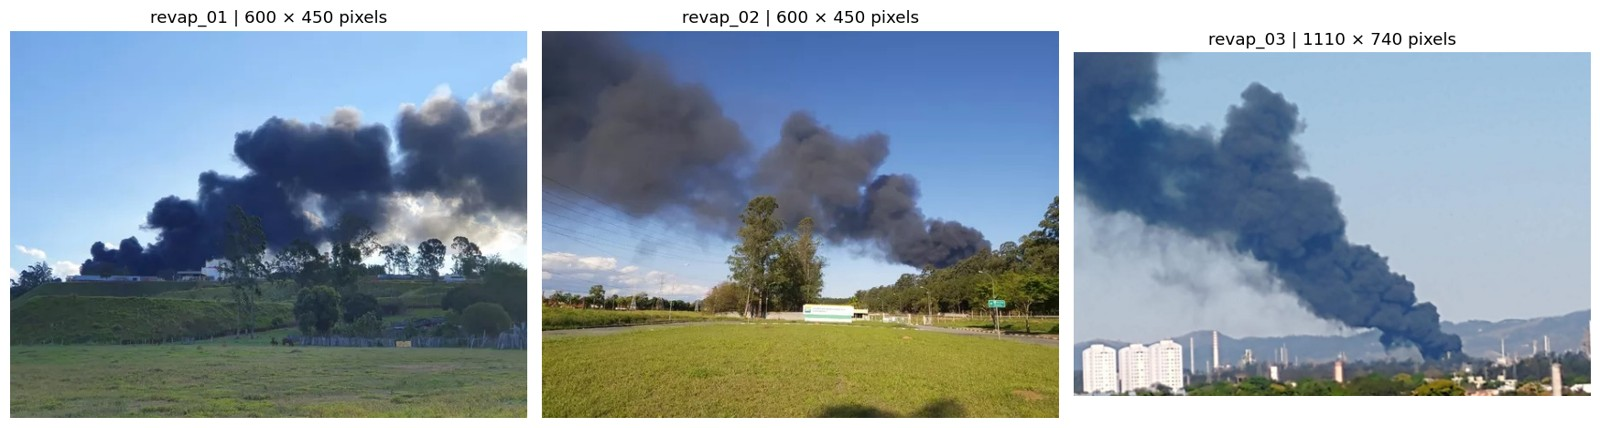

In [3]:
manifest = prepare_data()
config = load_config()
print('Arquivos verificados:', len(manifest['arquivos']))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (image_id, item) in zip(axes, config['imagens'].items()):
    image = read_rgb(ROOT / item['arquivo'])
    ax.imshow(image)
    ax.set_title(f"{image_id} | {image.shape[1]} × {image.shape[0]} pixels")
    ax.axis('off')
plt.tight_layout()
plt.show()
plt.close(fig)

## 3. Experimento: quatro configurações de prompts

| Configuração | Caixa | Pontos | Finalidade |
|---|---|---|---|
| P1 | Ampla | Nenhum | Linha de base e inspeção dos falsos positivos |
| P2 | Ajustada | Positivos ao longo da fumaça | Recuperar lobos e delimitar a região de interesse |
| P3 | Ajustada | Positivos + negativos em céu/árvores/edifícios | Excluir estruturas e testar os limites difusos |
| P4 | Igual à P3 | Iguais à P3 + logits anteriores | Refinar iterativamente a previsão |
| P5 | Da configuração final escolhida | Sem pontos novos | Remover apenas ilhas menores que 36 px sem semente positiva |

Os pontos foram definidos para cada fotografia por inspeção visual; são prompts supervisionados, não detecção automática da posição da fumaça. P4 altera o prompt de máscara (logits de P3), além dos prompts espaciais. P1–P3 já satisfazem os três experimentos solicitados.

O SAM pode devolver três máscaras candidatas. A seleção usa

\[
R_k = s_k + 2a_k - 0{,}5\ell_k,
\]

onde \(s_k\) é o score interno SAM, \(a_k\) a fração de pontos respeitados e \(\ell_k\) a fração da máscara fora da caixa. Esse critério é uma heurística explícita, não uma métrica de acurácia. Não usa a referência de avaliação. As candidatas e seus valores são exportados em `candidatos_sam.csv`.

**Controles:** mesma imagem RGB, modelo/checkpoint e seleção em todas as configurações; P1–P3 começam sem máscara anterior. P4 reaproveita somente o estado de P3. Reutilizar o embedding da imagem poupa cálculo, sem alterar os prompts.

In [4]:
def load_sam(checkpoint=None):
    import torch
    from segment_anything import SamPredictor, sam_model_registry
    torch.manual_seed(SEED)
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cuda":
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    p = Path(checkpoint or os.environ.get("SAM_CHECKPOINT", ROOT / "checkpoints/sam_vit_b_01ec64.pth"))
    download_checked("https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth", p,
                     CHECKPOINT_SHA256)
    # O checkpoint oficial é tratado como pesos; não carregamos arquivos arbitrários.
    sam = sam_model_registry["vit_b"](checkpoint=str(p))
    sam.to(device=device)
    sam.eval()
    print(f"SAM ViT-B | {device} | torch {torch.__version__} | checkpoint {sha256(p)[:16]}…")
    return SamPredictor(sam)


CHECKPOINT_SHA256 = "ec2df62732614e57411cdcf32a23ffdf28910380d03139ee0f4fcbe91eb8c912"


def prompt_arrays(spec, shape):
    """Coordenadas normalizadas → pixels da imagem após correção EXIF."""
    h, w = shape[:2]
    scale = np.array([w - 1, h - 1], dtype=np.float32)
    box = np.array(spec["box"], dtype=np.float32)
    if box.shape != (4,) or not np.all(np.isfinite(box)) or np.any((box < 0) | (box > 1)):
        raise ValueError("Caixa deve ter quatro coordenadas normalizadas entre 0 e 1.")
    if box[0] >= box[2] or box[1] >= box[3]:
        raise ValueError("Caixa inválida: requer x0 < x1 e y0 < y1.")
    box = box * np.tile(scale, 2)
    pos = np.array(spec.get("positive", []), dtype=np.float32).reshape(-1, 2)
    neg = np.array(spec.get("negative", []), dtype=np.float32).reshape(-1, 2)
    points = np.concatenate([pos, neg])
    if not np.all(np.isfinite(points)) or np.any((points < 0) | (points > 1)):
        raise ValueError("Pontos devem estar no intervalo [0, 1].")
    labels = np.r_[np.ones(len(pos)), np.zeros(len(neg))].astype(np.int32)
    return box, points * scale, labels


def configurations(item):
    p, n = item["positive"], item["negative"]
    return {
        "P1_caixa_ampla": {"box": item["loose_box"], "positive": [], "negative": []},
        "P2_caixa_positivos": {"box": item["box"], "positive": p, "negative": []},
        "P3_caixa_pos_neg": {"box": item["box"], "positive": p, "negative": n},
        "P4_refinamento_logits": {"box": item["box"], "positive": p, "negative": n},
    }


def prompt_consistency(mask, points, labels):
    if not len(points):
        return 1.0
    xy = np.rint(points).astype(int)
    return float(np.mean(mask[xy[:, 1], xy[:, 0]] == labels.astype(bool)))


def select_candidate(masks, scores, points, labels, box):
    """Seleção sem consultar referência manual: prompts + score interno do SAM.

    O score interno é uma estimativa do próprio modelo, não IoU medido.
    A área fora da caixa é somente diagnóstico/penalidade, não recorte forçado.
    """
    h, w = masks.shape[1:]
    in_box = np.zeros((h, w), bool)
    x0, y0, x1, y1 = np.rint(box).astype(int)
    in_box[y0:y1 + 1, x0:x1 + 1] = True
    records = []
    for k, (mask, score) in enumerate(zip(masks, scores)):
        consistency = prompt_consistency(mask, points, labels)
        leakage = float(np.sum(mask & ~in_box) / max(int(mask.sum()), 1))
        rank = float(score) + 2 * consistency - 0.5 * leakage
        records.append({"candidato": k, "score_interno_sam": float(score),
                        "consistencia_prompts": consistency, "fracao_fora_caixa": leakage,
                        "criterio_selecao": rank})
    return max(records, key=lambda r: r["criterio_selecao"])["candidato"], records


def clean_seeded(mask, points, labels, min_size=36):
    """Remove somente ilhas pequenas sem ponto positivo. Preserva furos e bordas.

    Não fecha buracos (árvores/céu), não impõe cor escura e não desenha uma máscara
    a partir da anotação de avaliação. Componentes grandes sem sementes ficam.
    """
    lab, _ = ndi.label(mask)
    sizes = np.bincount(lab.ravel())
    keep = sizes >= min_size
    keep[0] = False
    for (x, y), label in zip(np.rint(points).astype(int), labels):
        if label == 1 and lab[y, x]:
            keep[lab[y, x]] = True
    return keep[lab]


def infer_image(predictor, rgb, item):
    import torch
    results, candidates = {}, []
    start = time.perf_counter()
    with torch.inference_mode():
        predictor.set_image(rgb)
        lowres_previous = None
        for name, spec in configurations(item).items():
            box, points, labels = prompt_arrays(spec, rgb.shape)
            kwargs = {"box": box, "multimask_output": True}
            if len(points):
                kwargs.update(point_coords=points, point_labels=labels)
            if name.startswith("P4"):
                kwargs["mask_input"] = lowres_previous[None, :, :]
            masks, scores, logits = predictor.predict(**kwargs)
            selected, rows = select_candidate(masks, scores, points, labels, box)
            for row in rows:
                row.update(configuracao=name, selecionado=row["candidato"] == selected)
            candidates.extend(rows)
            results[name] = {"mask": masks[selected].astype(bool), "score": float(scores[selected]),
                             "box": box, "points": points, "labels": labels,
                             "candidate": selected}
            lowres_previous = logits[selected]
    chosen = results[item["final_config"]]
    final = dict(chosen)
    final["mask"] = clean_seeded(chosen["mask"], chosen["points"], chosen["labels"])
    results["P5_final_limpeza_minima"] = final
    seconds = time.perf_counter() - start
    return results, candidates, seconds

## 4. Métricas, referência aproximada e geometria

A referência poligonal foi traçada por inspeção visual assistida por IA antes da primeira inferência; **não é ground truth** e não foi revisada independentemente pelos integrantes. Não é usada para recortar a máscara ou escolher a candidata. Há uma faixa ignorada de 1,2% da menor dimensão nas bordas da referência, onde fumaça e fundo são ambíguos. O arquivo `dados/prompts.json` documenta os polígonos, oclusões e prompts.

\[
\mathrm{IoU}=\frac{TP}{TP+FP+FN},\qquad
\mathrm{Dice}=\frac{2TP}{2TP+FP+FN},\qquad
\mathrm{Precisão}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN}.
\]

Todos os índices referem-se aos **pixels válidos da referência aproximada**. Valores altos não provam segmentação perfeita. Usar as três imagens tanto para aprimorar prompts quanto para avaliar caracteriza análise de desenvolvimento, sem teste de generalização.

Área, centroide e projeções no eixo principal (PCA) são medidas em pixels. A orientação é matemática, com \(y\) para cima e módulo 180° (eixo sem sentido). A largura média é \(A/L\); o comprimento é a extensão projetada, não comprimento geodésico da pluma. Não há conversão para metros sem calibração da câmera e geometria da cena.

In [5]:
def rasterize(polygons, shape):
    h, w = shape[:2]
    mask = np.zeros((h, w), np.uint8)
    for poly in polygons:
        points = np.rint(np.array(poly) * [w - 1, h - 1]).astype(np.int32)
        cv2.fillPoly(mask, [points], 1)
    return mask.astype(bool)


def reference_mask(item, shape):
    ref = rasterize(item["reference_polygons"], shape)
    ref &= ~rasterize(item.get("reference_exclusions", []), shape)
    # Banda ignorada evita tratar fronteira difusa aproximada como verdade exata.
    radius = max(3, round(min(shape[:2]) * 0.012))
    dist_in = ndi.distance_transform_edt(ref)
    dist_out = ndi.distance_transform_edt(~ref)
    uncertain = np.where(ref, dist_in, dist_out) <= radius
    return ref, uncertain


def segmentation_metrics(mask, ref, valid=None):
    if mask.shape != ref.shape:
        raise ValueError("Máscara e referência devem ter as mesmas dimensões.")
    valid = np.ones_like(ref, bool) if valid is None else valid.astype(bool)
    if not valid.any():
        raise ValueError("Não há pixels válidos para avaliação.")
    m, r = mask[valid].astype(bool), ref[valid].astype(bool)
    tp, fp, fn = int(np.sum(m & r)), int(np.sum(m & ~r)), int(np.sum(~m & r))
    div = lambda a, b: float(a / b) if b else float("nan")
    return {"iou_ref_aprox": div(tp, tp + fp + fn), "dice_ref_aprox": div(2 * tp, 2 * tp + fp + fn),
            "precisao_ref_aprox": div(tp, tp + fp), "recall_ref_aprox": div(tp, tp + fn),
            "fp_ref_aprox_px": fp, "fn_ref_aprox_px": fn,
            "pixels_avaliados": int(valid.sum())}


def geometry(mask):
    y, x = np.nonzero(mask)
    if len(x) < 3:
        return {"area_px": len(x), "eixo_maior_px": np.nan, "largura_media_px": np.nan,
                "orientacao_imagem_graus_mod180": np.nan, "centroide_x_px": np.nan,
                "centroide_y_px": np.nan, "eixo_menor_px": np.nan}
    xy = np.column_stack([x, -y]).astype(float)  # eixo y matemático para cima
    centered = xy - xy.mean(axis=0)
    vals, vecs = np.linalg.eigh(np.cov(centered, rowvar=False))
    axis = vecs[:, np.argmax(vals)]
    projections = centered @ np.column_stack([axis, [-axis[1], axis[0]]])
    length, width = np.ptp(projections, axis=0)
    return {"area_px": int(mask.sum()), "eixo_maior_px": float(length),
            "eixo_menor_px": float(width), "largura_media_px": float(mask.sum() / max(length, 1)),
            "orientacao_imagem_graus_mod180": float(np.degrees(np.arctan2(axis[1], axis[0])) % 180),
            "centroide_x_px": float(x.mean()), "centroide_y_px": float(y.mean())}


def image_diagnostics(rgb, mask):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(float) / 255
    inner = mask & (ndi.distance_transform_edt(mask) > 3)
    ring = ndi.binary_dilation(mask, iterations=8) & ~mask
    a, b = gray[inner], gray[ring]
    if not len(a) or not len(b):
        return {"luminancia_media_pluma": np.nan, "contraste_local_diagnostico": np.nan}
    return {"luminancia_media_pluma": float(a.mean()),
            "contraste_local_diagnostico": float(abs(a.mean() - b.mean()) /
                                                np.sqrt((a.var() + b.var()) / 2 + 1e-8))}


def show_prompts(ax, result):
    x0, y0, x1, y1 = result["box"]
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=1.3, ec="#f5b83c"))
    for value, color, marker in [(1, "#33ef9b", "*"), (0, "#ff4a62", "x")]:
        pts = result["points"][result["labels"] == value]
        if len(pts):
            ax.scatter(*pts.T, c=color, marker=marker, s=55, linewidths=1.3,
                       label="positivo" if value else "negativo")


def overlay(rgb, mask, alpha=0.45):
    image = rgb.copy().astype(float)
    image[mask] = (1 - alpha) * image[mask] + alpha * np.array([255, 72, 45])
    return np.clip(image, 0, 255).astype(np.uint8)


def plot_comparison(rgb, results, name, path=None):
    rows = len(results)
    fig, axes = plt.subplots(rows, 3, figsize=(15, rows * 3.7), squeeze=False)
    for i, (config, result) in enumerate(results.items()):
        mask = result["mask"]
        axes[i, 0].imshow(rgb)
        show_prompts(axes[i, 0], result)
        axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].imshow(overlay(rgb, mask))
        if mask.any() and not mask.all():
            axes[i, 2].contour(mask, levels=[0.5], colors=["#fff285"], linewidths=0.6)
        axes[i, 0].set_title(f"{config}\nOriginal + prompts")
        axes[i, 1].set_title(f"Máscara binária | {mask.mean():.1%} da imagem")
        axes[i, 2].set_title(f"Sobreposição | score interno SAM {result['score']:.3f}")
        for ax in axes[i]:
            ax.set_axis_off()
    fig.suptitle(f"{name} — comparação controlada de prompts", fontsize=16)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    if path:
        fig.savefig(path, dpi=130, bbox_inches="tight")
    return fig


def plot_evaluation(rgb, mask, ref, uncertain, title, path):
    valid = ~uncertain
    errors = np.zeros_like(rgb)
    errors[mask & ref & valid] = [50, 190, 120]
    errors[mask & ~ref & valid] = [240, 60, 70]
    errors[~mask & ref & valid] = [60, 140, 250]
    errors[uncertain] = [245, 205, 75]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    axes[0].imshow(overlay(rgb, ref))
    axes[0].set_title("Referência aproximada (não é ground truth)")
    axes[1].imshow(overlay(rgb, mask))
    axes[1].set_title("Máscara final SAM + limpeza mínima")
    axes[2].imshow(errors)
    axes[2].set_title("Verde: acordo; vermelho: inclusão\nAzul: omissão; amarelo: borda ignorada")
    for ax in axes:
        ax.set_axis_off()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=130, bbox_inches="tight")
    return fig


def run_segmentation(predictor, config, display=True):
    metrics, candidates_all, finals = [], [], {}
    for image_id, item in config["imagens"].items():
        rgb = read_rgb(ROOT / item["arquivo"])
        results, candidates, seconds = infer_image(predictor, rgb, item)
        for c in candidates:
            candidates_all.append({"imagem": image_id, **c})
        ref, uncertain = reference_mask(item, rgb.shape)
        folder = OUT / image_id
        folder.mkdir(parents=True, exist_ok=True)
        Image.fromarray(ref.astype(np.uint8) * 255).save(folder / "referencia_aproximada.png")
        Image.fromarray(uncertain.astype(np.uint8) * 255).save(folder / "borda_ignorada.png")
        for name, r in results.items():
            mask = r["mask"]
            Image.fromarray(mask.astype(np.uint8) * 255).save(folder / f"{name}_binaria.png")
            Image.fromarray(overlay(rgb, mask)).save(folder / f"{name}_sobreposta.png")
            metrics.append({"imagem": image_id, "configuracao": name,
                            "score_interno_sam": r["score"],
                            "consistencia_prompts": prompt_consistency(mask, r["points"], r["labels"]),
                            "tempo_total_imagem_s": seconds,
                            **segmentation_metrics(mask, ref, ~uncertain),
                            **geometry(mask), **image_diagnostics(rgb, mask)})
        fig = plot_comparison(rgb, results, image_id, folder / "comparacao_prompts.png")
        if display:
            plt.show()
        plt.close(fig)
        final = results["P5_final_limpeza_minima"]["mask"]
        fig = plot_evaluation(rgb, final, ref, uncertain, image_id, folder / "avaliacao_final.png")
        if display:
            plt.show()
        plt.close(fig)
        finals[image_id] = {"rgb": rgb, "results": results, "reference": ref,
                            "uncertain": uncertain, "final": final}
        print(f"{image_id}: {rgb.shape[1]}×{rgb.shape[0]} px; {seconds:.1f} s; final: {item['final_config']}")
    table = pd.DataFrame(metrics)
    table.to_csv(OUT / "metricas_segmentacao.csv", index=False)
    pd.DataFrame(candidates_all).to_csv(OUT / "candidatos_sam.csv", index=False)
    (OUT / "prompts_utilizados.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
    return table, finals

SAM ViT-B | cpu | torch 2.14.1+cpu | checkpoint ec2df62732614e57…
revap_01: 600×450 px; 8.9 s; final: P4_refinamento_logits
revap_02: 600×450 px; 7.8 s; final: P4_refinamento_logits
revap_03: 1110×740 px; 8.3 s; final: P3_caixa_pos_neg
Atenção: score interno SAM e IoU da referência aproximada são grandezas distintas.


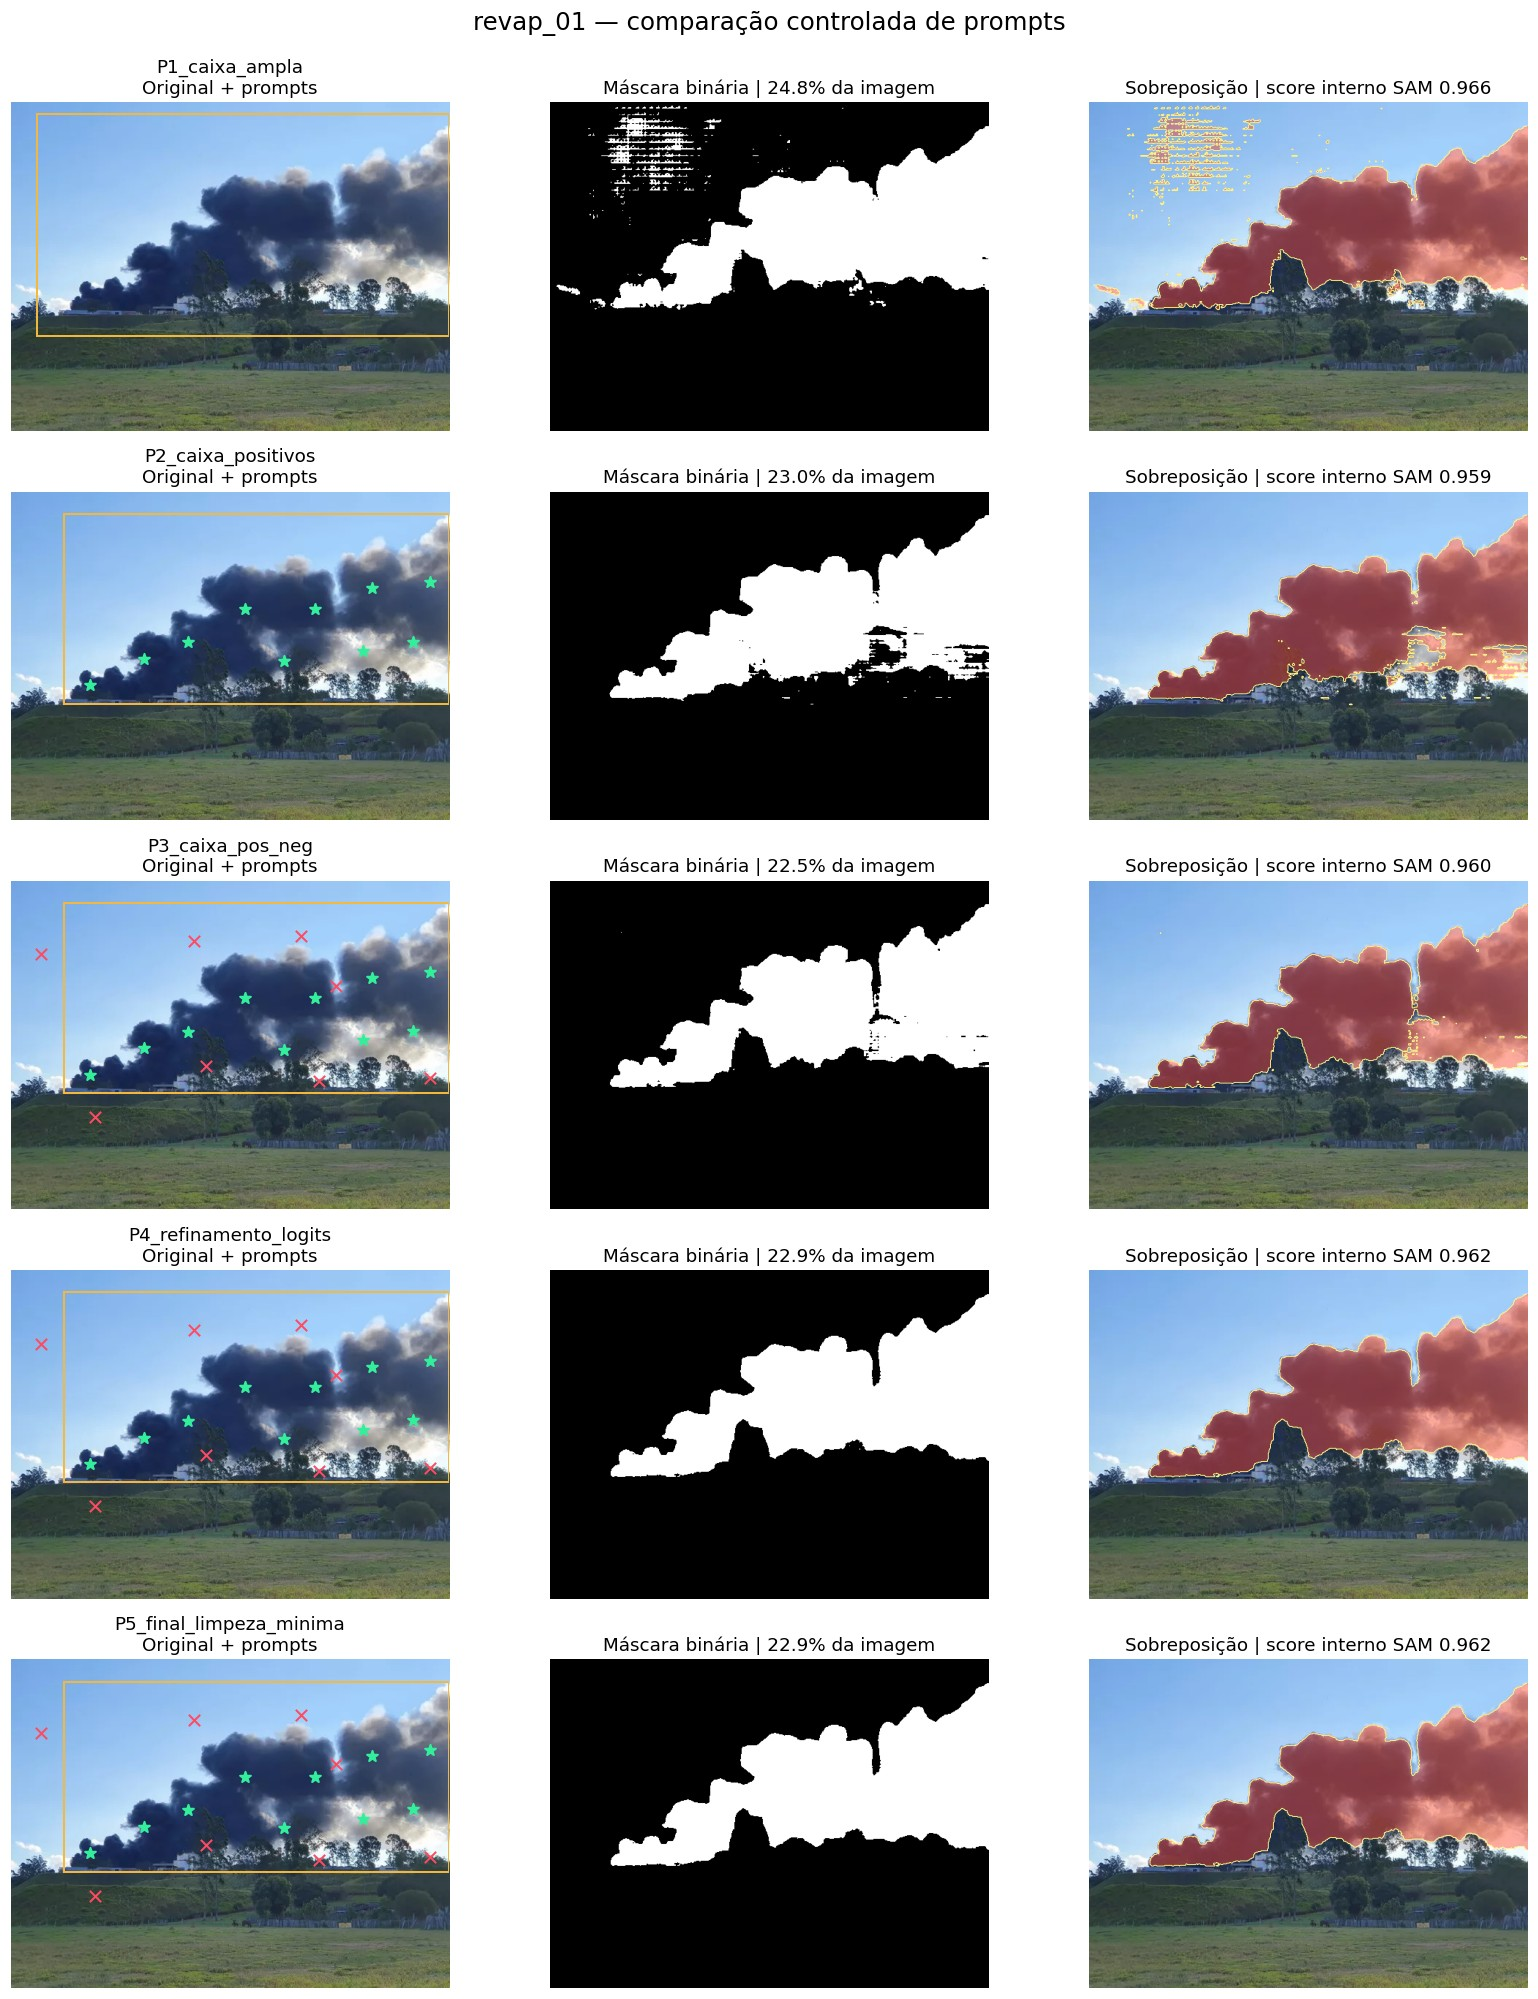

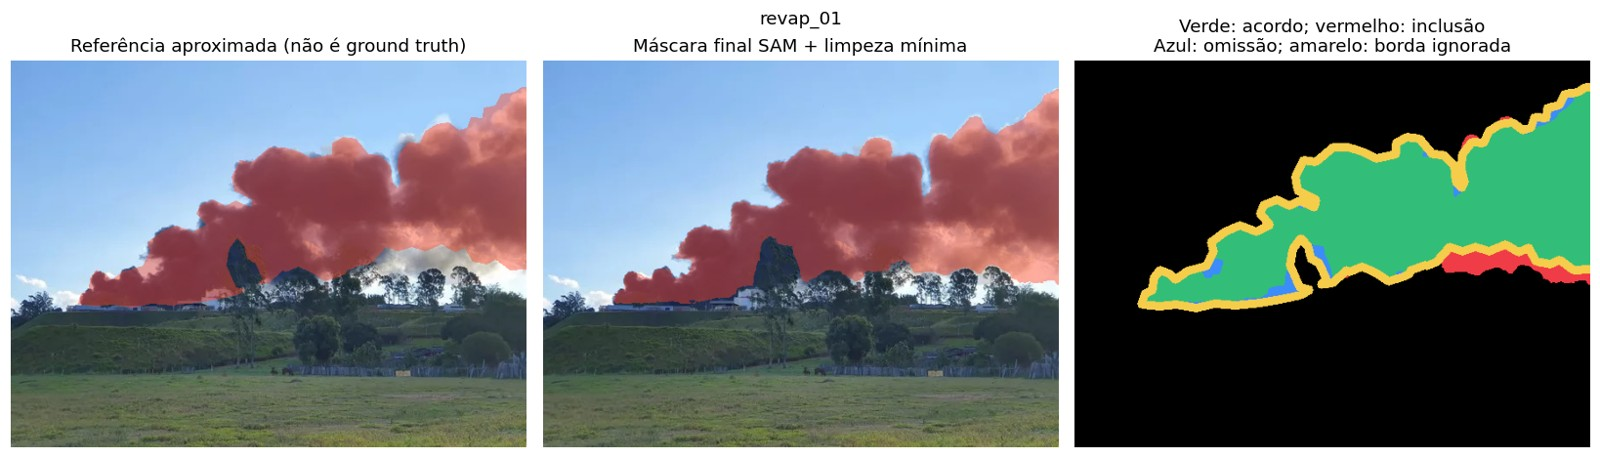

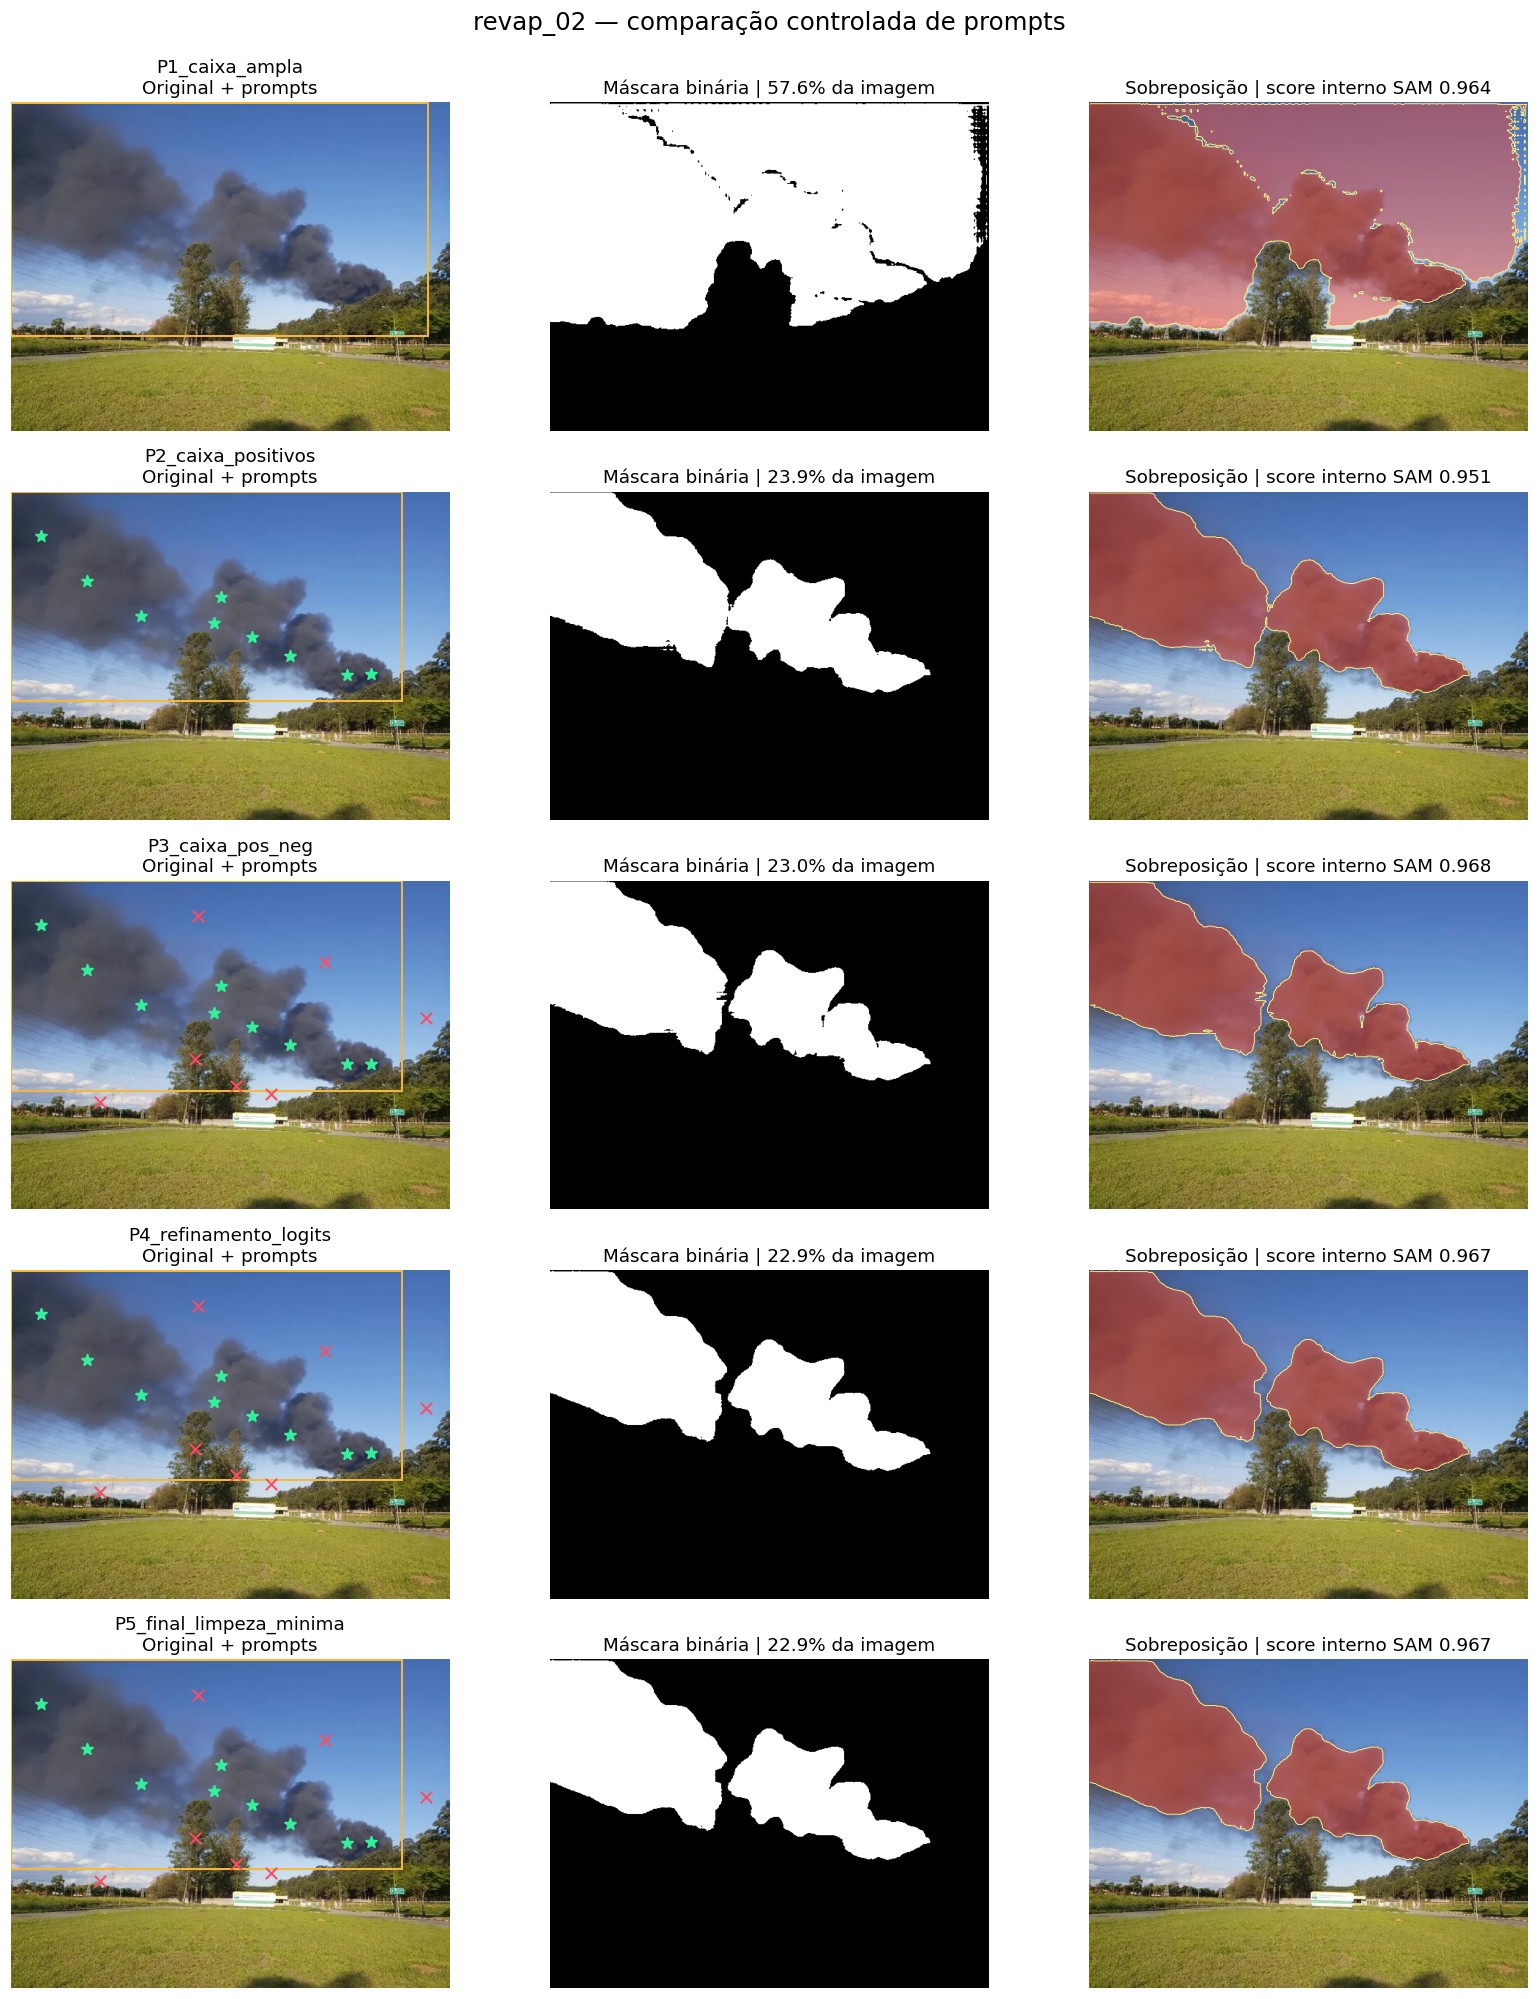

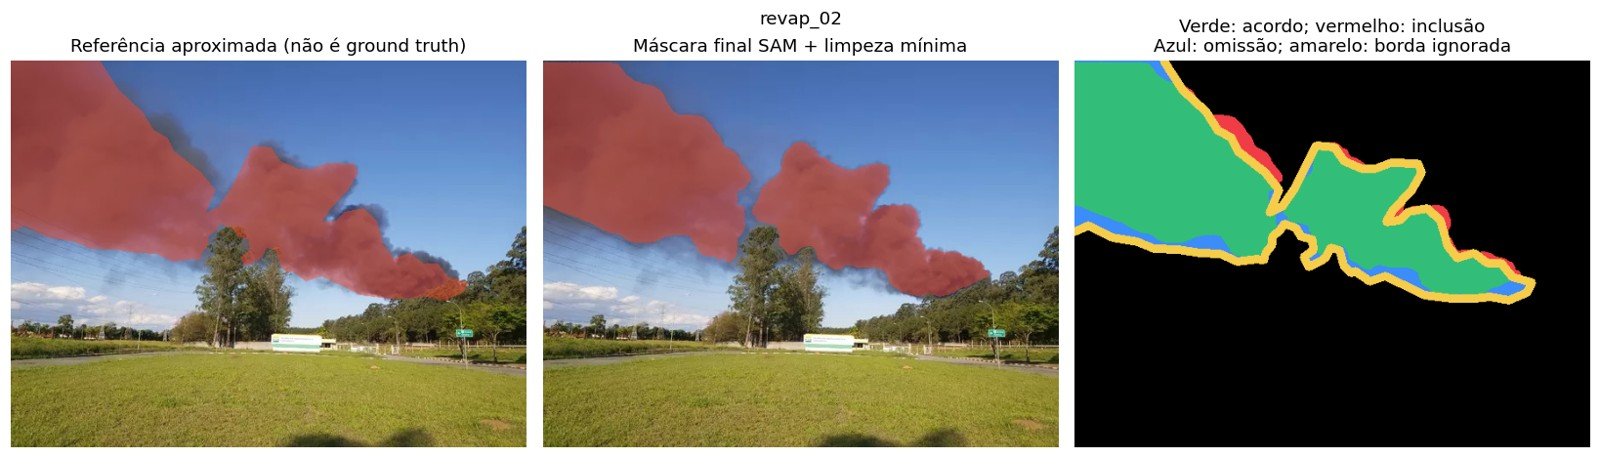

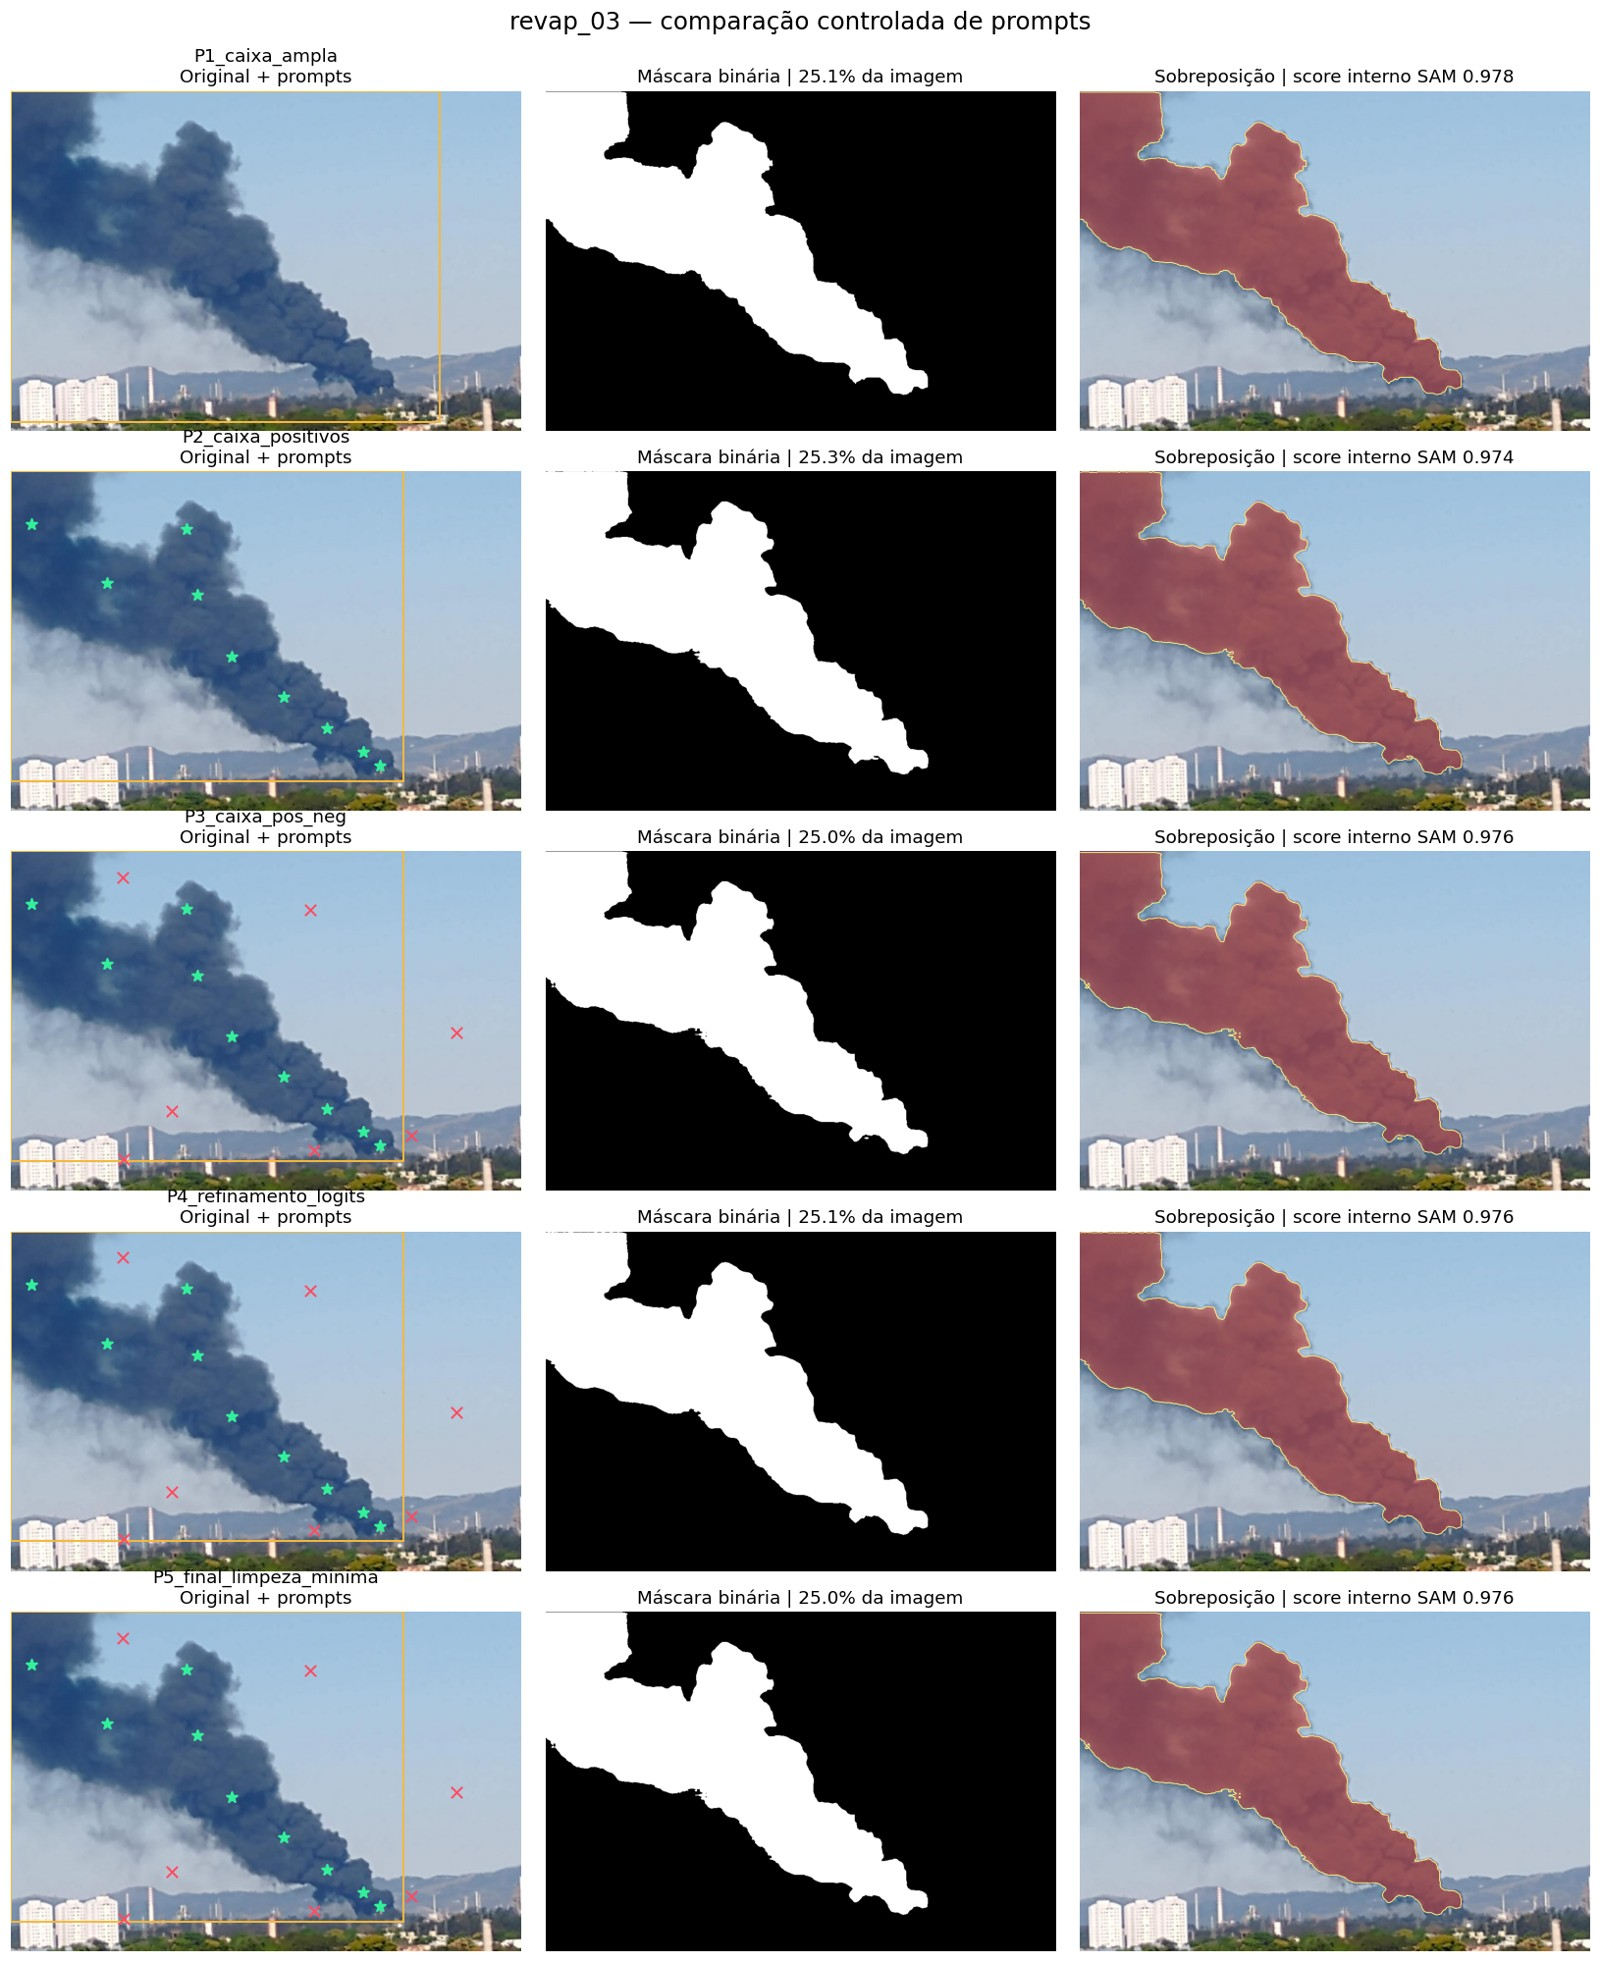

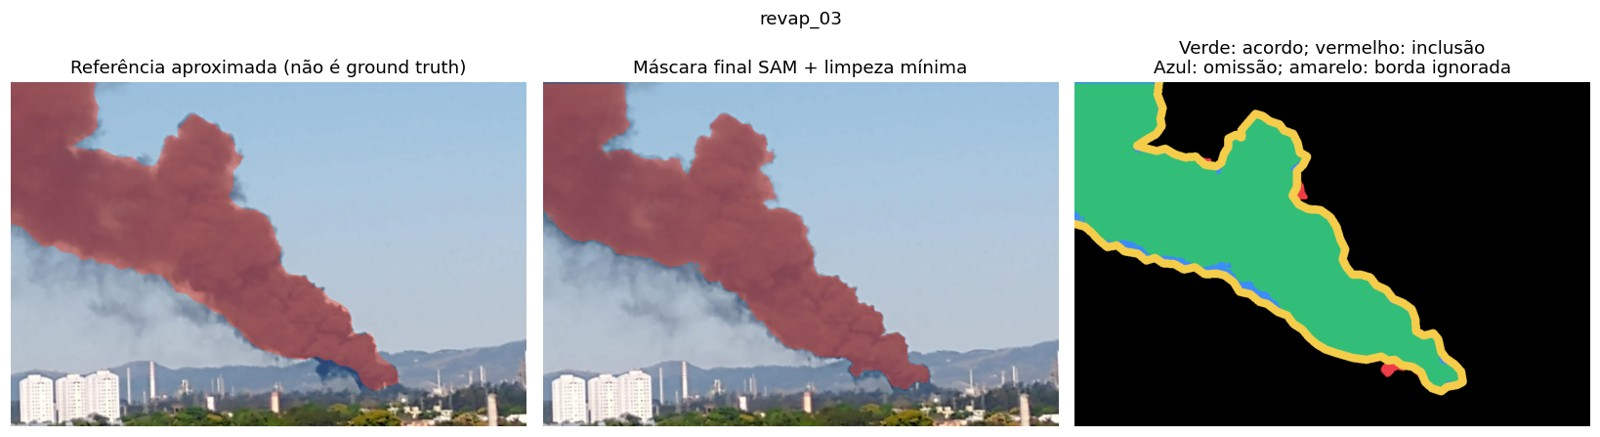

,imagem,configuracao,score_interno_sam,consistencia_prompts,iou_ref_aprox,dice_ref_aprox,precisao_ref_aprox,recall_ref_aprox,area_px
0,revap_01,P1_caixa_ampla,0.9664,1.0,0.8530,0.9207,0.8755,0.9708,66876
1,revap_01,P2_caixa_positivos,0.9593,1.0,0.9042,0.9497,0.9442,0.9553,62099
2,revap_01,P3_caixa_pos_neg,0.9601,1.0,0.9144,0.9553,0.9509,0.9597,60869
3,revap_01,P4_refinamento_logits,0.9623,1.0,0.9205,0.9586,0.9458,0.9717,61820
4,revap_01,P5_final_limpeza_minima,0.9623,1.0,0.9205,0.9586,0.9459,0.9717,61817
5,revap_02,P1_caixa_ampla,0.9638,1.0,0.3925,0.5637,0.3952,0.9826,155513
6,revap_02,P2_caixa_positivos,0.9514,1.0,0.9077,0.9516,0.9558,0.9475,64444
7,revap_02,P3_caixa_pos_neg,0.9679,1.0,0.8977,0.9461,0.9617,0.9310,62233
8,revap_02,P4_refinamento_logits,0.9668,1.0,0.8925,0.9432,0.9608,0.9262,61843
9,revap_02,P5_final_limpeza_minima,0.9668,1.0,0.8925,0.9432,0.9608,0.9262,61843


In [6]:
predictor = load_sam()
metricas, resultados = run_segmentation(predictor, config, display=True)
from IPython.display import display, Markdown
colunas = ['imagem', 'configuracao', 'score_interno_sam', 'consistencia_prompts',
           'iou_ref_aprox', 'dice_ref_aprox', 'precisao_ref_aprox', 'recall_ref_aprox', 'area_px']
display(metricas[colunas].round(4))
print('Atenção: score interno SAM e IoU da referência aproximada são grandezas distintas.')

## 5. Leitura crítica dos resultados

**revap_01:** fumaça escura sobre céu azul favorece a separação, mas a fumaça clara à direita e os intervalos de céu entre filamentos são ambíguos. As árvores ocultam a base; negativos evitam incorporá-las. A caixa ampla pode incluir nuvens e ruído no céu. O refinamento reduz pequenos artefatos; filamentos de baixa opacidade continuam incertos.

**revap_02:** a caixa ampla confunde fumaça com céu e pode produzir uma máscara muito extensa mesmo com alto score interno. Positivos distribuídos recuperam a cadeia de lobos. Árvores e fios cortam a região; negativos na vegetação corrigem a oclusão, mas podem retirar fumaça nas bordas translúcidas. A pluma sai pelo topo/esquerda do enquadramento. Dois positivos inicialmente próximos de árvore/borda foram corrigidos por inspeção de consistência antes da versão final; os experimentos publicados usam os pontos corrigidos.

**revap_03:** a caixa já captura bem o núcleo. Negativos tornam explícito o que deve ficar fora, mas não garantem melhora: as métricas aproximadas e a inspeção podem mostrar ganho nulo ou queda. Compressão, coloração azulada e filamentos translúcidos dificultam a delimitação exata. Prédios e serra próximos à origem não fazem parte da fumaça.

**Iluminação e contraste:** contraluz, reflexos e espalhamento tornam fumaça clara semelhante às nuvens. A fumaça escura contrasta com céu azul e pode se confundir com árvores/sombras. Um limiar de cor escura descartaria partes claras da pluma, por isso não é aplicado. O contraste local é apenas um diagnóstico entre máscara e anel externo; o anel contém cena heterogênea e não mede propriedades físicas da fumaça.

**A máscara cobre a pluma?** O núcleo visível é o alvo; as figuras original/binária/sobreposição e o mapa de inclusões/omissões permitem avaliar cobertura e contaminação. As tabelas abaixo quantificam essa análise aproximada. Árvores ocluem a fumaça: não se inventa a parte escondida. As máscaras brutas são preservadas e a limpeza não preenche todos os furos, nem dilata o contorno.

In [7]:
comparacao = metricas.pivot(index='imagem', columns='configuracao', values='iou_ref_aprox')
display(comparacao.round(4))
for image_id, item in config['imagens'].items():
    sub = metricas[metricas.imagem == image_id]
    base = sub[sub.configuracao == 'P1_caixa_ampla'].iloc[0]
    final = sub[sub.configuracao == 'P5_final_limpeza_minima'].iloc[0]
    display(Markdown(f"**{image_id}:** IoU aproximado P1 → final: {base.iou_ref_aprox:.3f} → {final.iou_ref_aprox:.3f}; "
                     f"Δ = {final.iou_ref_aprox-base.iou_ref_aprox:+.3f}. "
                     f"Inclusões: {int(final.fp_ref_aprox_px)} px; omissões: {int(final.fn_ref_aprox_px)} px "
                     f"fora da faixa ignorada. Escolha: `{item['final_config']}`. {item['justificativa_final']}"))

configuracao,P1_caixa_ampla,P2_caixa_positivos,P3_caixa_pos_neg,P4_refinamento_logits,P5_final_limpeza_minima
imagem,,,,,
revap_01,0.8530,0.9042,0.9144,0.9205,0.9205
revap_02,0.3925,0.9077,0.8977,0.8925,0.8925
revap_03,0.9745,0.9730,0.9704,0.9723,0.9706


**revap_01:** IoU aproximado P1 → final: 0.853 → 0.921; Δ = +0.067. Inclusões: 2984 px; omissões: 1518 px fora da faixa ignorada. Escolha: `P4_refinamento_logits`. Inspeção visual: o refinamento preserva a coluna e a fumaça clara à direita, reduz pequenos artefatos e mantém as oclusões por árvores. Persistem ambiguidades de céu entre filamentos.

**revap_02:** IoU aproximado P1 → final: 0.392 → 0.893; Δ = +0.500. Inclusões: 2200 px; omissões: 4294 px fora da faixa ignorada. Escolha: `P4_refinamento_logits`. Inspeção visual: o refinamento exclui o céu incluído por P1, conserva os lobos principais e respeita a oclusão das árvores. A faixa translúcida inferior continua ambígua; o score interno não é o critério único de avaliação.

**revap_03:** IoU aproximado P1 → final: 0.974 → 0.971; Δ = -0.004. Inclusões: 1283 px; omissões: 4482 px fora da faixa ignorada. Escolha: `P3_caixa_pos_neg`. Inspeção visual: P3 explicita a exclusão do céu, prédios e serra; o núcleo permanece semelhante ao de P1. A caixa sozinha já tem alto acordo aproximado e prompts adicionais não aumentam esse índice. Nenhuma versão resolve todos os filamentos translúcidos.

## 6. Ajuste opcional por cliques no Colab

A entrega executa automaticamente os prompts já registrados. Para explorar novos prompts, mude `ABRIR_EDITOR` para `True` e execute a célula abaixo no Colab. Clique em fumaça (+) e fundo (−); use Shift + arraste para redefinir a caixa. Clique em **Salvar e continuar** para executar a nova comparação.

A alteração é salva separadamente em `resultados/prompts_editados_<imagem>.json`; não substitui a avaliação oficial nem seus polígonos. Para mudar a versão oficial, revise `dados/prompts.json`, atualize seu hash em `dados/manifesto.json` e execute novamente todas as etapas.

In [8]:
def edit_prompts_colab(rgb, item):
    """Editor opcional no Colab: cliques +/− e arraste da caixa com Shift.

    Bloqueia somente quando chamado explicitamente; não interrompe Executar tudo.
    Retorna a configuração editada, sem alterar silenciosamente os originais.
    """
    import base64
    import io
    import copy
    from google.colab.output import eval_js
    buff = io.BytesIO()
    Image.fromarray(rgb).save(buff, format="PNG")
    initial = {"positive": item["positive"], "negative": item["negative"], "box": item["box"]}
    payload = {"data": "data:image/png;base64," + base64.b64encode(buff.getvalue()).decode(),
               "initial": initial}
    script = r"""
    new Promise((resolve) => {
      const payload = __PAYLOAD__;
      const state = JSON.parse(JSON.stringify(payload.initial));
      const host = document.createElement('div');
      host.style.cssText='padding:12px;font:14px sans-serif;background:#f5f5f5';
      const help = document.createElement('p');
      help.textContent='Clique para pontos. Shift + arraste para nova caixa. Verde = fumaça; vermelho = fundo.';
      host.appendChild(help);
      const mode = document.createElement('select');
      for (const [v,t] of [['positive','+ Fumaça'],['negative','− Fundo']]) {
        const o = document.createElement('option'); o.value=v; o.textContent=t; mode.appendChild(o);
      }
      host.appendChild(mode);
      const undo = document.createElement('button'); undo.textContent='Desfazer ponto'; host.appendChild(undo);
      const reset = document.createElement('button'); reset.textContent='Restaurar'; host.appendChild(reset);
      const save = document.createElement('button'); save.textContent='Salvar e continuar'; host.appendChild(save);
      const canvas = document.createElement('canvas'); canvas.style.cssText='display:block;max-width:100%;cursor:crosshair;margin-top:10px';
      host.appendChild(canvas); document.body.appendChild(host);
      const ctx = canvas.getContext('2d'); const image = new Image(); let drag=null; let history=[];
      const draw=()=>{
        ctx.drawImage(image,0,0,canvas.width,canvas.height);
        const [a,b,c,d]=state.box;
        ctx.strokeStyle='#ffcd33'; ctx.lineWidth=2; ctx.strokeRect(a*canvas.width,b*canvas.height,(c-a)*canvas.width,(d-b)*canvas.height);
        for(const key of ['positive','negative']) for(const [x,y] of state[key]){
          ctx.beginPath(); ctx.arc(x*canvas.width,y*canvas.height,5,0,Math.PI*2);
          ctx.fillStyle=key==='positive'?'#00e98b':'#ff3d60'; ctx.fill();ctx.strokeStyle='black';ctx.stroke();
        }
      };
      image.onload=()=>{canvas.width=Math.min(900,image.width);canvas.height=Math.round(image.height*canvas.width/image.width);draw();};
      image.src=payload.data;
      const xy=e=>{const r=canvas.getBoundingClientRect();return [Math.max(0,Math.min(1,(e.clientX-r.left)/r.width)),Math.max(0,Math.min(1,(e.clientY-r.top)/r.height))];};
      canvas.onpointerdown=e=>{if(e.shiftKey){drag=xy(e);canvas.setPointerCapture(e.pointerId);}else{state[mode.value].push(xy(e));history.push(mode.value);draw();}};
      canvas.onpointerup=e=>{if(drag){const p=xy(e);if(Math.abs(p[0]-drag[0])>.005&&Math.abs(p[1]-drag[1])>.005)state.box=[Math.min(p[0],drag[0]),Math.min(p[1],drag[1]),Math.max(p[0],drag[0]),Math.max(p[1],drag[1])];drag=null;draw();}};
      undo.onclick=()=>{if(history.length)state[history.pop()].pop();draw();};
      reset.onclick=()=>{Object.assign(state,JSON.parse(JSON.stringify(payload.initial)));history=[];draw();};
      save.onclick=()=>{host.remove();resolve(state);};
    })
    """.replace("__PAYLOAD__", json.dumps(payload))
    edited = copy.deepcopy(item)
    edited.update(eval_js(script))
    prompt_arrays(edited, rgb.shape)
    return edited

In [9]:
ABRIR_EDITOR = False  # não bloqueia "Executar tudo"
IMAGEM_EDITAR = 'revap_02'
if ABRIR_EDITOR:
    rgb_editar = resultados[IMAGEM_EDITAR]['rgb']
    item_editado = edit_prompts_colab(rgb_editar, config['imagens'][IMAGEM_EDITAR])
    novos_resultados, _, tempo = infer_image(predictor, rgb_editar, item_editado)
    fig = plot_comparison(rgb_editar, novos_resultados, IMAGEM_EDITAR + ' — prompts editados')
    plt.show()
    plt.close(fig)
    destino = OUT / f'prompts_editados_{IMAGEM_EDITAR}.json'
    destino.write_text(json.dumps(item_editado, indent=2, ensure_ascii=False))
    print('Prompts experimentais salvos:', destino)
else:
    print('Editor opcional desativado. A análise principal está completa.')

Editor opcional desativado. A análise principal está completa.


## 7. Vento ERA5: série completa, unidades e convenções

O arquivo recebido contém **8 horários × 5 latitudes × 5 longitudes × 2 componentes = 400 valores**. A primeira amostra (15h BRT) precede as 15h15 e permite interpolação temporal. A última é 22h BRT, equivalente a 01h UTC do dia seguinte. O código valida unidades, limites espaciais, finitude e duplicações; ordena latitude/longitude antes da interpolação.

\[
U=\sqrt{u^2+v^2},\quad
\theta_{\rm mat}=\operatorname{atan2}(v,u),\quad
\alpha_{\rm para}=\operatorname{atan2}(u,v),\quad
\alpha_{\rm de}=(\alpha_{\rm para}+180^\circ)\bmod360^\circ.
\]

Os ângulos são convertidos para graus e normalizados em \([0,360)\). A direção meteorológica indica **de onde vem** o vento; o azimute de transporte indica **para onde vai**. Em calmaria abaixo de 0,1 m/s, direção é indefinida (NaN). Exportam-se todas as horas, com vizinho mais próximo e interpolação bilinear; o mapa mostra somente um instante para não sobrepor setas de horas diferentes.

**Limitação:** u10/v10 são vento a 10 m, não vento na altitude da pluma. A grade de 0,25° não resolve a circulação de cada rua. Sem horário/orientação das câmeras não cabe correlacionar os três ângulos em pixels com a série de azimutes geográficos.

In [10]:
def wind_quantities(u, v, calm_threshold=0.1):
    u, v = np.asarray(u, float), np.asarray(v, float)
    speed = np.hypot(u, v)
    vector_angle = np.degrees(np.arctan2(v, u)) % 360  # anti-horário desde leste
    toward = np.degrees(np.arctan2(u, v)) % 360         # horário desde norte
    from_direction = (toward + 180) % 360
    calm = speed < calm_threshold
    return speed, np.where(calm, np.nan, vector_angle), np.where(calm, np.nan, toward), np.where(calm, np.nan, from_direction)


def load_wind(path, lat=LAT, lon=LON):
    with xr.open_dataset(path) as raw:
        ds = raw.load()
    rename = {a: b for a, b in [("lat", "latitude"), ("lon", "longitude"), ("valid_time", "time")]
              if a in ds.coords and b not in ds.coords}
    ds = ds.rename(rename)
    for name in ["latitude", "longitude", "time", "u10", "v10"]:
        if name not in ds:
            raise ValueError(f"NetCDF sem {name}")
    if float(ds.longitude.max()) > 180:
        ds = ds.assign_coords(longitude=(ds.longitude + 180) % 360 - 180)
    ds = ds.sortby("latitude").sortby("longitude").sortby("time")
    if not (float(ds.latitude.min()) <= lat <= float(ds.latitude.max()) and
            float(ds.longitude.min()) <= lon <= float(ds.longitude.max())):
        raise ValueError("Fonte fora do domínio ERA5; extrapolação proibida.")
    if pd.Index(ds.time.values).has_duplicates:
        raise ValueError("Horários duplicados no ERA5.")
    if not np.isfinite(ds.u10).all() or not np.isfinite(ds.v10).all():
        raise ValueError("ERA5 contém vento ausente ou não finito.")
    for v in ["u10", "v10"]:
        if ds[v].attrs.get("units") not in ["m s-1", "m/s", "m s**-1"]:
            raise ValueError(f"Unidade de {v} deve ser m/s, recebida {ds[v].attrs.get('units')}")
    grid = ds.to_dataframe().reset_index()
    grid["velocidade_m_s"], grid["angulo_desde_leste_graus"], grid["azimute_para_graus"], grid["direcao_de_graus"] = wind_quantities(grid.u10, grid.v10)
    grid.to_csv(OUT / "era5_grade_completa.csv", index=False)
    nearest = ds.sel(latitude=lat, longitude=lon, method="nearest")
    bilinear = ds.interp(latitude=lat, longitude=lon)
    tables = []
    for method, point in [("vizinho_mais_proximo", nearest), ("bilinear", bilinear)]:
        table = point.to_dataframe().reset_index()
        table["metodo"] = method
        table["time_utc"] = pd.to_datetime(table["time"], utc=True)
        table["time_local"] = table["time_utc"].dt.tz_convert("America/Sao_Paulo")
        table["velocidade_m_s"], table["angulo_desde_leste_graus"], table["azimute_para_graus"], table["direcao_de_graus"] = wind_quantities(table.u10, table.v10)
        tables.append(table)
    wind = pd.concat(tables, ignore_index=True)
    wind.to_csv(OUT / "era5_fonte.csv", index=False)
    print(f"ERA5: {dict(ds.sizes)}; grade mais próxima: {float(nearest.latitude):.3f}, {float(nearest.longitude):.3f}")
    return ds, wind


def plot_wind(ds, wind):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    # Um único instante: sobrepor 8 horários no mesmo mapa seria enganoso.
    first = ds.isel(time=0)
    xx, yy = np.meshgrid(first.longitude, first.latitude)
    q = axes[0].quiver(xx, yy, first.u10, first.v10, np.hypot(first.u10, first.v10), cmap="viridis")
    axes[0].scatter(LON, LAT, marker="*", s=160, color="#e95a35", label="ponto representativo REVAP")
    axes[0].set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="Vento a 10 m | 29/09/2019, 15h BRT")
    axes[0].set_aspect(1 / math.cos(math.radians(LAT)))
    axes[0].legend(fontsize=8)
    fig.colorbar(q, ax=axes[0], label="m/s")
    for method, sub in wind.groupby("metodo"):
        axes[1].plot(sub.time_local.dt.strftime("%H:%M"), sub.velocidade_m_s, "o-", label=method)
    axes[1].set(xlabel="Hora local (UTC−3)", ylabel="Velocidade a 10 m (m/s)", title="Sensibilidade à extração espacial")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(OUT / "vento_era5.png", dpi=140)
    return fig

ERA5: {'time': 8, 'latitude': 5, 'longitude': 5}; grade mais próxima: -23.250, -45.750


,metodo,time_utc,time_local,u10,v10,velocidade_m_s,angulo_desde_leste_graus,azimute_para_graus,direcao_de_graus
0,vizinho_mais_proximo,2019-09-29 18:00:00+00:00,2019-09-29 15:00:00-03:00,-0.5318,2.3581,2.4173,102.7081,347.2919,167.2919
1,vizinho_mais_proximo,2019-09-29 19:00:00+00:00,2019-09-29 16:00:00-03:00,-0.9944,2.5535,2.7403,111.2770,338.7230,158.7230
2,vizinho_mais_proximo,2019-09-29 20:00:00+00:00,2019-09-29 17:00:00-03:00,-1.5428,2.3968,2.8504,122.7683,327.2317,147.2317
3,vizinho_mais_proximo,2019-09-29 21:00:00+00:00,2019-09-29 18:00:00-03:00,-1.6002,1.8115,2.4171,131.4561,318.5439,138.5439
4,vizinho_mais_proximo,2019-09-29 22:00:00+00:00,2019-09-29 19:00:00-03:00,-1.6474,1.1450,2.0062,145.1987,304.8013,124.8013
5,vizinho_mais_proximo,2019-09-29 23:00:00+00:00,2019-09-29 20:00:00-03:00,-1.8716,1.1102,2.1761,149.3250,300.6750,120.6750
6,vizinho_mais_proximo,2019-09-30 00:00:00+00:00,2019-09-29 21:00:00-03:00,-1.7348,1.0293,2.0172,149.3178,300.6822,120.6822
7,vizinho_mais_proximo,2019-09-30 01:00:00+00:00,2019-09-29 22:00:00-03:00,-1.7431,0.8301,1.9307,154.5348,295.4652,115.4652
8,bilinear,2019-09-29 18:00:00+00:00,2019-09-29 15:00:00-03:00,-0.4703,2.5127,2.5563,100.6011,349.3989,169.3989
9,bilinear,2019-09-29 19:00:00+00:00,2019-09-29 16:00:00-03:00,-0.9746,2.7696,2.9361,109.3869,340.6131,160.6131


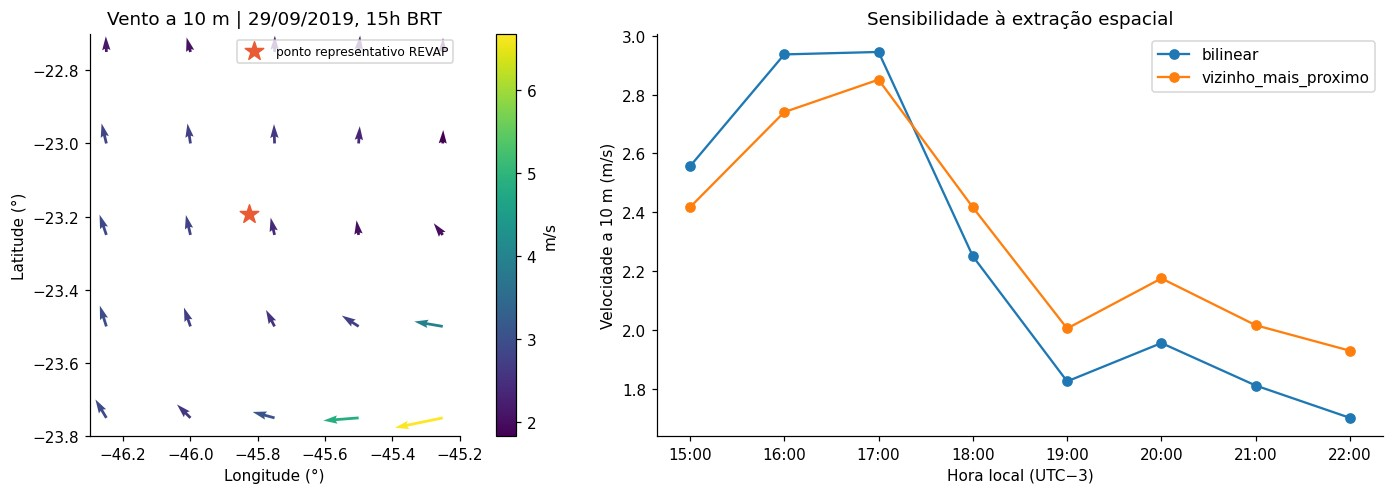

In [11]:
ds_era5, vento = load_wind(ROOT / 'dados/Vento_ERA5_REVAP_2019.nc')
display(vento[['metodo', 'time_utc', 'time_local', 'u10', 'v10', 'velocidade_m_s',
               'angulo_desde_leste_graus', 'azimute_para_graus', 'direcao_de_graus']].round(4))
fig = plot_wind(ds_era5, vento)
plt.show()
plt.close(fig)

## 8. Extensão: solução transiente de advecção–difusão 2D

Esta extensão desenvolve o modelo de transporte mencionado na proposta e no notebook de referência. **Não é necessária para produzir a máscara SAM, nem calibra a pluma das fotografias.** Como emissão, altura e difusividade reais não são conhecidas, os parâmetros a seguir são hipóteses declaradas.

Para um traçador passivo com vento espacialmente uniforme e variável no tempo:

\[
\frac{\partial c}{\partial t}+u(t)\frac{\partial c}{\partial x}+v(t)\frac{\partial c}{\partial y}
=K\left(\frac{\partial^2 c}{\partial x^2}+\frac{\partial^2 c}{\partial y^2}\right)+qG_{\sigma_0}(x,y),\qquad c(x,y,t_0)=0.
\]

O domínio matemático é o plano infinito, com decaimento no infinito. A fonte é uma gaussiana normalizada \(G_{\sigma_0}\) centrada na origem (regularização da fonte pontual). Para uma emissão no instante \(\tau\):

\[
X(\tau,t)=\int_\tau^t u(s)\,ds,\quad Y(\tau,t)=\int_\tau^t v(s)\,ds,\quad
\sigma^2(\tau,t)=\sigma_0^2+2K(t-\tau).
\]

Pela solução de Green, a emissão contínua resulta em

\[
c(x,y,t)=\int_{t_0}^{t}\frac{q}{2\pi\sigma^2(\tau,t)}
\exp\left[-\frac{(x-X(\tau,t))^2+(y-Y(\tau,t))^2}{2\sigma^2(\tau,t)}\right]d\tau.
\]

Calculamos a integral do interpolante linear de vento exatamente em cada intervalo. A integral de emissão usa quadratura de ponto médio (60 s), sem solver explícito de diferenças finitas e, portanto, sem restrição CFL desse tipo de solver. O campo é amostrado em uma janela finita para visualização e balanço de massa.

**Cenário:** emissão de 15h15 a 22h; \(q=1\) unidade de traçador/s, \(K=20\) m²/s, \(\sigma_0=100\) m. \(c\) é traçador por m², não concentração atmosférica em μg/m³. Não resolvemos empuxo, altura, deposição, reação química ou CFD 3D. Verificamos massa total \(M=q(t-t_0)\), simetria sem vento, segundo momento da difusão e sensibilidade ao passo temporal 120/60 s. Essas verificações testam a implementação; não validam o cenário contra o incêndio.

In [12]:
def integrate_wind(wind_table, query_utc):
    """Integral exata do interpolante linear de u(t), v(t), sem extrapolação."""
    base = pd.to_datetime(wind_table.time_utc, utc=True)
    origin = base.min()
    t = np.asarray((base - origin).dt.total_seconds(), float)
    q = np.asarray((pd.to_datetime(query_utc, utc=True) - origin).total_seconds(), float)
    if np.any(q < t.min()) or np.any(q > t.max()) or np.any(np.diff(t) <= 0):
        raise ValueError("Instantes fora da série de vento ou série não estritamente crescente.")
    output = []
    for values in [np.asarray(wind_table.u10), np.asarray(wind_table.v10)]:
        dt = np.diff(t)
        slope = np.diff(values) / dt
        accumulated = np.r_[0., np.cumsum(0.5 * (values[1:] + values[:-1]) * dt)]
        idx = np.clip(np.searchsorted(t, q, side="right") - 1, 0, len(t) - 2)
        delta = q - t[idx]
        output.append(accumulated[idx] + values[idx] * delta + 0.5 * slope[idx] * delta ** 2)
    return np.column_stack(output)


def gaussian_puffs(wind, start, end, x, y, diffusivity=20., rate=1., sigma0=100., release_dt=60.):
    """Convolução de Green da advecção–difusão 2D com vento uniforme variável.

    Emissão constante, massa unitária por segundo; integração por ponto médio
    no tempo de liberação. Não estima concentração atmosférica observada.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start.tz is None or end.tz is None:
        raise ValueError("Início/fim precisam de fuso explícito.")
    duration = (end - start).total_seconds()
    if duration <= 0 or diffusivity < 0 or rate <= 0 or sigma0 <= 0 or release_dt <= 0:
        raise ValueError("Parâmetros físicos/temporais inválidos.")
    steps = max(1, math.ceil(duration / release_dt))
    dt = duration / steps
    ages = duration - (np.arange(steps) + 0.5) * dt
    releases = start + pd.to_timedelta((np.arange(steps) + 0.5) * dt, unit="s")
    integrated = integrate_wind(wind, releases.append(pd.DatetimeIndex([end])))
    centers = integrated[-1] - integrated[:-1]
    xx, yy = np.meshgrid(x, y)
    c = np.zeros_like(xx, float)
    for age, (cx, cy) in zip(ages, centers):
        variance = sigma0 ** 2 + 2 * diffusivity * age
        c += rate * dt / (2 * np.pi * variance) * np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * variance))
    return c, centers, rate * duration


def run_physics(wind):
    sub = wind[wind.metodo == "bilinear"].copy()
    start, end = "2019-09-29T18:15:00Z", "2019-09-30T01:00:00Z"
    x = np.linspace(-65000, 15000, 321)
    y = np.linspace(-15000, 65000, 321)
    c, centers, mass = gaussian_puffs(sub, start, end, x, y)
    numerical_mass = float(np.trapezoid(np.trapezoid(c, x=x, axis=1), x=y))
    relative_error = abs(numerical_mass - mass) / mass
    if relative_error > 0.02:
        raise RuntimeError(f"Balanço de massa fora da tolerância: {relative_error:.2%}")
    # Verificação de convergência da quadratura temporal em pontos representativos.
    probe_x = np.linspace(-50000, 5000, 71)
    probe_y = np.linspace(-5000, 50000, 71)
    coarse, _, _ = gaussian_puffs(sub, start, end, probe_x, probe_y, release_dt=120.)
    fine, _, _ = gaussian_puffs(sub, start, end, probe_x, probe_y, release_dt=60.)
    convergence = float(np.linalg.norm(coarse - fine) / np.linalg.norm(fine))
    checks = {"inicio_utc": start, "fim_utc": end, "K_hipotetico_m2_s": 20.,
              "q_unidades_tracador_s": 1., "sigma0_hipotetico_m": 100.,
              "massa_emitida_unidades": mass, "massa_integrada_unidades": numerical_mass,
              "erro_relativo_massa": relative_error, "diferenca_relativa_dt120_dt60": convergence,
              "nota": "Cenário didático; sem calibração, ascensão térmica, deposição ou validação fotográfica."}
    (OUT / "verificacao_adveccao_difusao.json").write_text(json.dumps(checks, indent=2, ensure_ascii=False))
    np.savez_compressed(OUT / "cenario_didatico_adveccao_difusao.npz", x_m=x, y_m=y, tracer=c)
    fig, ax = plt.subplots(figsize=(7.5, 6))
    field = ax.pcolormesh(x / 1000, y / 1000, np.log10(np.maximum(c, 1e-12)), cmap="magma", shading="auto", vmin=-9)
    ax.plot(centers[:, 0] / 1000, centers[:, 1] / 1000, color="cyan", lw=1, label="centros dos puffs")
    ax.scatter(0, 0, color="white", marker="*", s=100, label="fonte aproximada")
    ax.set(xlabel="Distância leste (km)", ylabel="Distância norte (km)",
           title="Cenário hipotético 2D | vento ERA5 bilinear\nK = 20 m²/s; emissão unitária; 22h BRT", aspect="equal")
    ax.legend(fontsize=8)
    fig.colorbar(field, ax=ax, label="log₁₀ do traçador (unidade/m²); não concentração real")
    fig.tight_layout()
    fig.savefig(OUT / "cenario_didatico.png", dpi=140)
    return checks, fig

Conservação de massa e convergência temporal dentro da tolerância de 2%.


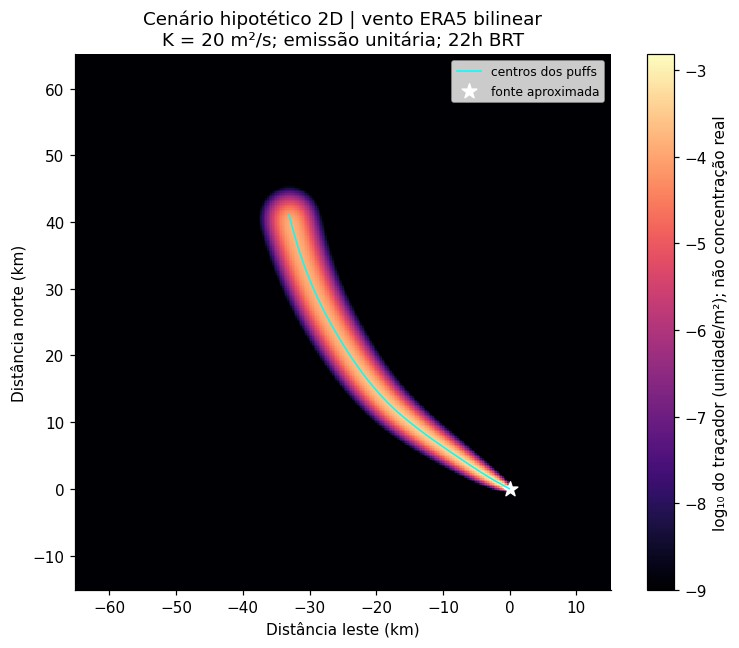

,valor
inicio_utc,2019-09-29T18:15:00Z
fim_utc,2019-09-30T01:00:00Z
K_hipotetico_m2_s,20.0
q_unidades_tracador_s,1.0
sigma0_hipotetico_m,100.0
massa_emitida_unidades,24300.0
massa_integrada_unidades,24302.272599
erro_relativo_massa,0.000094
diferenca_relativa_dt120_dt60,0.000116
nota,"Cenário didático; sem calibração, ascensão tér..."


In [13]:
verificacao_fisica, fig = run_physics(vento)
plt.show()
plt.close(fig)
display(pd.DataFrame([verificacao_fisica]).T.rename(columns={0: 'valor'}))
assert verificacao_fisica['erro_relativo_massa'] < 0.02
assert verificacao_fisica['diferenca_relativa_dt120_dt60'] < 0.02
print('Conservação de massa e convergência temporal dentro da tolerância de 2%.')

## 9. Entrega, arquivos e conclusão

O diretório `resultados/` contém máscaras binárias 0/255, sobreposições, comparação de todas as configurações, mapa de acordo/inclusões/omissões, CSV de métricas, candidatos SAM, série ERA5, parâmetros físicos e ambiente de execução. O ZIP reúne esses resultados.

O experimento mostra que prompts adequados podem corrigir falhas grandes da caixa, principalmente na segunda foto; adicionar pontos não garante melhoria em toda imagem. A máscara final representa uma decisão operacional sobre a parte visível da fumaça. Uma avaliação de acurácia exigiria anotação humana independente e, para bordas difusas, critérios explícitos ou rótulos de opacidade. A evolução física não é inferível dessas fotografias sem calibração e horários.

Os nomes e RAs vêm da proposta. A elaboração do código, dos prompts e da referência aproximada contou com assistência de IA; cabe aos integrantes revisar a interpretação e os critérios da atividade.

In [14]:
def write_report(table, finals, config, wind, physics):
    lines = ["# REVAP — avaliação dos experimentos SAM", "",
             "Eduardo Nascimento — RA 168800 · Rebeka Wolpi — RA 176598", "",
             "## Método e limites", "",
             "SAM oficial ViT-B; quatro configurações reais por foto e uma limpeza mínima. "
             "P1 usa caixa ampla, P2 caixa ajustada e pontos positivos, P3 acrescenta negativos, "
             "P4 reutiliza logits de P3 para refinamento. Os três candidatos SAM são registrados. "
             "A seleção automática usa consistência com prompts, score interno e vazamento da caixa, "
             "sem consultar os polígonos de avaliação. A configuração final está em prompts.json.", "",
             "Os polígonos de referência foram traçados por inspeção visual assistida por IA antes "
             "da inferência. São aproximações para discussão, sem revisão humana independente. "
             "A faixa de 1,2% da menor dimensão ao redor das bordas é ignorada nas métricas. "
             "IoU/Dice abaixo medem acordo com essa aproximação, não acurácia validada. "
             "O score interno SAM também não é acurácia medida. Os prompts e as referências "
             "usam as mesmas três imagens de desenvolvimento; não existe conjunto de teste externo.", ""]
    for image_id, item in config["imagens"].items():
        sub = table[table.imagem == image_id]
        lines.extend([f"## {image_id}", "", item["analise_visual"], "",
                      "| Configuração | IoU aprox. | Dice aprox. | Precisão aprox. | Recall aprox. | Área (px) |",
                      "|---|---:|---:|---:|---:|---:|"])
        for _, r in sub.iterrows():
            lines.append(f"| {r.configuracao} | {r.iou_ref_aprox:.3f} | {r.dice_ref_aprox:.3f} | {r.precisao_ref_aprox:.3f} | {r.recall_ref_aprox:.3f} | {int(r.area_px)} |")
        first, final = sub.iloc[0], sub.iloc[-1]
        delta = final.iou_ref_aprox - first.iou_ref_aprox
        lines.extend(["", f"Variação do IoU aproximado P1 → final: {delta:+.3f}. "
                      f"Final escolhida: {item['final_config']}; justificativa: {item['justificativa_final']}", "",
                      f"A máscara final deixa {int(final.fn_ref_aprox_px)} pixels da referência aproximada de fora "
                      f"e inclui {int(final.fp_ref_aprox_px)} pixels fora dela, na região avaliada. "
                      "Esses números dependem da anotação e não resolvem a ambiguidade da fumaça translúcida.", "",
                      f"![Comparação]({image_id}/comparacao_prompts.png)", "",
                      f"![Avaliação]({image_id}/avaliacao_final.png)", ""])
    lines.extend(["## Discussão da imagem e dos prompts", "",
                  "Fumaça não é um objeto opaco com borda única. Há transições graduais, céu entre "
                  "fragmentos e oclusões por árvores, prédios e fios. Pontos positivos distribuídos "
                  "incluem lobos desconectados; negativos em céu/vegetação limitam inclusões. Uma "
                  "caixa retangular sozinha não descreve essas formas. Pontos negativos em regiões "
                  "ambíguas também podem excluir fumaça real. Não há ganho garantido ao adicionar prompts.", "",
                  "Iluminação de fundo e espalhamento tornam a fumaça clara semelhante às nuvens. "
                  "Sombra e fumaça escura produzem contraste elevado com céu azul, mas podem se "
                  "confundir com vegetação e edifícios. O contraste local exportado é diagnóstico: "
                  "o anel externo pode conter outros objetos e não é uma medida física da atmosfera. "
                  "Não se usa limiar de cor escura, pois ele descartaria fumaça clara. Não se preenchem "
                  "todos os buracos nem se expande a máscara indiscriminadamente.", "",
                  "As medidas são em pixels. PCA fornece orientação de um eixo sem sentido (módulo "
                  "180°), não rumo geográfico ou direção do vento. Perspectiva e ausência de escala, "
                  "posição/orientação da câmera e horário impedem conversão para metros, comparação "
                  "direta com azimutes ERA5 e cálculo de correlação válida. Não se estima concentração "
                  "a partir da intensidade da fotografia.", "",
                  "## ERA5 e equações", "",
                  "O arquivo recebido foi validado (8 horários, grade 5×5, u10/v10 em m/s). "
                  "A série completa é preservada. Exportam-se grade, vizinho mais próximo e "
                  "interpolação bilinear. Velocidade = hypot(u,v); ângulo matemático = atan2(v,u); "
                  "azimute para onde vai = atan2(u,v); direção meteorológica de onde vem = azimute + 180°. "
                  "Direção é indefinida em calmaria. A primeira amostra (15h) antecede as 15h15 e "
                  "serve de suporte à interpolação; não há extrapolação após as 22h.", "",
                  "O cenário adicional resolve advecção–difusão 2D com vento espacialmente uniforme "
                  "e variável no tempo pela convolução da solução de Green gaussiana. A integral "
                  "do vento linear por partes é exata; a emissão contínua usa quadratura de ponto "
                  "médio com passo 60 s. K=20 m²/s e largura inicial 100 m são hipóteses ilustrativas, "
                  "emissão = 1 unidade de traçador/s. Não representam parâmetros medidos do incêndio. "
                  "O modelo não resolve empuxo, pluma 3D, turbulência urbana ou deposição.", "",
                  f"Balanço de massa: erro relativo {physics['erro_relativo_massa']:.3%}; "
                  f"diferença relativa da quadratura 120 s / 60 s: {physics['diferenca_relativa_dt120_dt60']:.3%}.", "",
                  "## Proveniência", "",
                  "As três fotografias foram fornecidas pelo estudante, sem URLs originais, créditos "
                  "ou metadados verificáveis de câmera/horário. A associação ao evento é a informada "
                  "na atividade, não uma autenticação independente. Originais preservados byte a byte; "
                  "SHA-256 em dados/manifesto.json. Dados e narrativa do evento: Proposta_REVAP_2019.pdf "
                  "e metadados internos do NetCDF recebido. A posição representa a refinaria, não "
                  "um tanque confirmado.", "",
                  "SAM: https://github.com/facebookresearch/segment-anything ; artigo "
                  "https://arxiv.org/abs/2304.02643 ; notebook de referência da disciplina: "
                  "https://github.com/rjlobosco/modelagem_computacional/blob/main/Projeto_Pluma_ERA5_Colab.ipynb ; "
                  "ERA5: https://doi.org/10.24381/cds.adbb2d47 .", ""])
    (OUT / "relatorio.md").write_text("\n".join(lines))
    versions = {"python": platform.python_version(), "numpy": np.__version__, "opencv": cv2.__version__,
                "pandas": pd.__version__, "xarray": xr.__version__}
    import torch
    versions["torch"] = torch.__version__
    versions["cuda_disponivel"] = torch.cuda.is_available()
    versions["sam_checkpoint_sha256"] = CHECKPOINT_SHA256
    (OUT / "ambiente_execucao.json").write_text(json.dumps(versions, indent=2))
    archive = ROOT / "resultados_revap.zip"
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(OUT.rglob("*")):
            if p.is_file():
                z.write(p, p.relative_to(ROOT))
    return archive

In [15]:
arquivo_zip = write_report(metricas, resultados, config, vento, verificacao_fisica)
texto_relatorio = (OUT / 'relatorio.md').read_text()
display(Markdown('\n'.join(linha for linha in texto_relatorio.splitlines() if not linha.startswith('!['))))
print('Resultados completos:', arquivo_zip)
# Para baixar no Colab, descomente:
# from google.colab import files
# files.download(str(arquivo_zip))

Resultados completos: /workspace/scratch/d966eccdb9bb/ModelagemComputacional/resultados_revap.zip


# REVAP — avaliação dos experimentos SAM

Eduardo Nascimento — RA 168800 · Rebeka Wolpi — RA 176598

## Método e limites

SAM oficial ViT-B; quatro configurações reais por foto e uma limpeza mínima. P1 usa caixa ampla, P2 caixa ajustada e pontos positivos, P3 acrescenta negativos, P4 reutiliza logits de P3 para refinamento. Os três candidatos SAM são registrados. A seleção automática usa consistência com prompts, score interno e vazamento da caixa, sem consultar os polígonos de avaliação. A configuração final está em prompts.json.

Os polígonos de referência foram traçados por inspeção visual assistida por IA antes da inferência. São aproximações para discussão, sem revisão humana independente. A faixa de 1,2% da menor dimensão ao redor das bordas é ignorada nas métricas. IoU/Dice abaixo medem acordo com essa aproximação, não acurácia validada. O score interno SAM também não é acurácia medida. Os prompts e as referências usam as mesmas três imagens de desenvolvimento; não existe conjunto de teste externo.

## revap_01

A pluma escura contrasta com o céu azul. Na direita há fumaça clara, reflexos e céu visível entre lobos; árvores ocultam a borda inferior. O contorno translúcido não tem limite único. Pontos positivos cobrem o núcleo e os lobos à direita; negativos marcam céu e vegetação. A caixa ampla permite observar vazamento na linha do horizonte.

| Configuração | IoU aprox. | Dice aprox. | Precisão aprox. | Recall aprox. | Área (px) |
|---|---:|---:|---:|---:|---:|
| P1_caixa_ampla | 0.853 | 0.921 | 0.876 | 0.971 | 66876 |
| P2_caixa_positivos | 0.904 | 0.950 | 0.944 | 0.955 | 62099 |
| P3_caixa_pos_neg | 0.914 | 0.955 | 0.951 | 0.960 | 60869 |
| P4_refinamento_logits | 0.920 | 0.959 | 0.946 | 0.972 | 61820 |
| P5_final_limpeza_minima | 0.921 | 0.959 | 0.946 | 0.972 | 61817 |

Variação do IoU aproximado P1 → final: +0.067. Final escolhida: P4_refinamento_logits; justificativa: Inspeção visual: o refinamento preserva a coluna e a fumaça clara à direita, reduz pequenos artefatos e mantém as oclusões por árvores. Persistem ambiguidades de céu entre filamentos.

A máscara final deixa 1518 pixels da referência aproximada de fora e inclui 2984 pixels fora dela, na região avaliada. Esses números dependem da anotação e não resolvem a ambiguidade da fumaça translúcida.



## revap_02

A fumaça é cinza e menos contrastada que na primeira foto. Dois agrupamentos visuais se encontram em uma transição translúcida; árvores encobrem a parte central, fios atravessam o céu e nuvens claras aparecem perto do horizonte. Negativos na vegetação ajudam a excluir a oclusão sem preencher o espaço atrás das árvores. A pluma sai pelo topo/esquerda: sua extensão total está fora do enquadramento.

| Configuração | IoU aprox. | Dice aprox. | Precisão aprox. | Recall aprox. | Área (px) |
|---|---:|---:|---:|---:|---:|
| P1_caixa_ampla | 0.392 | 0.564 | 0.395 | 0.983 | 155513 |
| P2_caixa_positivos | 0.908 | 0.952 | 0.956 | 0.947 | 64444 |
| P3_caixa_pos_neg | 0.898 | 0.946 | 0.962 | 0.931 | 62233 |
| P4_refinamento_logits | 0.893 | 0.943 | 0.961 | 0.926 | 61843 |
| P5_final_limpeza_minima | 0.893 | 0.943 | 0.961 | 0.926 | 61843 |

Variação do IoU aproximado P1 → final: +0.500. Final escolhida: P4_refinamento_logits; justificativa: Inspeção visual: o refinamento exclui o céu incluído por P1, conserva os lobos principais e respeita a oclusão das árvores. A faixa translúcida inferior continua ambígua; o score interno não é o critério único de avaliação.

A máscara final deixa 4294 pixels da referência aproximada de fora e inclui 2200 pixels fora dela, na região avaliada. Esses números dependem da anotação e não resolvem a ambiguidade da fumaça translúcida.



## revap_03

A imagem aproximada apresenta compressão e menor contraste de cor entre céu e bordas azuladas da fumaça. Há filamentos translúcidos na parte inferior e prédios/serra próximos da fonte. Pontos positivos ao longo do eixo e negativos na serra, nos prédios e no céu procuram preservar a coluna principal. A margem esquerda recorta a pluma e a perspectiva impede interpretar o ângulo da imagem como rumo geográfico.

| Configuração | IoU aprox. | Dice aprox. | Precisão aprox. | Recall aprox. | Área (px) |
|---|---:|---:|---:|---:|---:|
| P1_caixa_ampla | 0.974 | 0.987 | 0.993 | 0.982 | 206544 |
| P2_caixa_positivos | 0.973 | 0.986 | 0.991 | 0.982 | 207740 |
| P3_caixa_pos_neg | 0.970 | 0.985 | 0.993 | 0.977 | 205439 |
| P4_refinamento_logits | 0.972 | 0.986 | 0.993 | 0.979 | 205965 |
| P5_final_limpeza_minima | 0.971 | 0.985 | 0.993 | 0.977 | 205408 |

Variação do IoU aproximado P1 → final: -0.004. Final escolhida: P3_caixa_pos_neg; justificativa: Inspeção visual: P3 explicita a exclusão do céu, prédios e serra; o núcleo permanece semelhante ao de P1. A caixa sozinha já tem alto acordo aproximado e prompts adicionais não aumentam esse índice. Nenhuma versão resolve todos os filamentos translúcidos.

A máscara final deixa 4482 pixels da referência aproximada de fora e inclui 1283 pixels fora dela, na região avaliada. Esses números dependem da anotação e não resolvem a ambiguidade da fumaça translúcida.



## Discussão da imagem e dos prompts

Fumaça não é um objeto opaco com borda única. Há transições graduais, céu entre fragmentos e oclusões por árvores, prédios e fios. Pontos positivos distribuídos incluem lobos desconectados; negativos em céu/vegetação limitam inclusões. Uma caixa retangular sozinha não descreve essas formas. Pontos negativos em regiões ambíguas também podem excluir fumaça real. Não há ganho garantido ao adicionar prompts.

Iluminação de fundo e espalhamento tornam a fumaça clara semelhante às nuvens. Sombra e fumaça escura produzem contraste elevado com céu azul, mas podem se confundir com vegetação e edifícios. O contraste local exportado é diagnóstico: o anel externo pode conter outros objetos e não é uma medida física da atmosfera. Não se usa limiar de cor escura, pois ele descartaria fumaça clara. Não se preenchem todos os buracos nem se expande a máscara indiscriminadamente.

As medidas são em pixels. PCA fornece orientação de um eixo sem sentido (módulo 180°), não rumo geográfico ou direção do vento. Perspectiva e ausência de escala, posição/orientação da câmera e horário impedem conversão para metros, comparação direta com azimutes ERA5 e cálculo de correlação válida. Não se estima concentração a partir da intensidade da fotografia.

## ERA5 e equações

O arquivo recebido foi validado (8 horários, grade 5×5, u10/v10 em m/s). A série completa é preservada. Exportam-se grade, vizinho mais próximo e interpolação bilinear. Velocidade = hypot(u,v); ângulo matemático = atan2(v,u); azimute para onde vai = atan2(u,v); direção meteorológica de onde vem = azimute + 180°. Direção é indefinida em calmaria. A primeira amostra (15h) antecede as 15h15 e serve de suporte à interpolação; não há extrapolação após as 22h.

O cenário adicional resolve advecção–difusão 2D com vento espacialmente uniforme e variável no tempo pela convolução da solução de Green gaussiana. A integral do vento linear por partes é exata; a emissão contínua usa quadratura de ponto médio com passo 60 s. K=20 m²/s e largura inicial 100 m são hipóteses ilustrativas, emissão = 1 unidade de traçador/s. Não representam parâmetros medidos do incêndio. O modelo não resolve empuxo, pluma 3D, turbulência urbana ou deposição.

Balanço de massa: erro relativo 0.009%; diferença relativa da quadratura 120 s / 60 s: 0.012%.

## Proveniência

As três fotografias foram fornecidas pelo estudante, sem URLs originais, créditos ou metadados verificáveis de câmera/horário. A associação ao evento é a informada na atividade, não uma autenticação independente. Originais preservados byte a byte; SHA-256 em dados/manifesto.json. Dados e narrativa do evento: Proposta_REVAP_2019.pdf e metadados internos do NetCDF recebido. A posição representa a refinaria, não um tanque confirmado.

SAM: https://github.com/facebookresearch/segment-anything ; artigo https://arxiv.org/abs/2304.02643 ; notebook de referência da disciplina: https://github.com/rjlobosco/modelagem_computacional/blob/main/Projeto_Pluma_ERA5_Colab.ipynb ; ERA5: https://doi.org/10.24381/cds.adbb2d47 .

## Referências e proveniência

1. [Notebook inicial da disciplina — pluma, ERA5 e CFD](https://github.com/rjlobosco/modelagem_computacional/blob/main/Projeto_Pluma_ERA5_Colab.ipynb). Roteiro de referência; a segmentação SAM e sua avaliação foram acrescentadas neste trabalho.
2. [Meta/Facebook Research — Segment Anything](https://github.com/facebookresearch/segment-anything), implementação e checkpoint ViT-B oficiais; [Kirillov et al. (2023)](https://arxiv.org/abs/2304.02643). Dependência `segment-anything==1.0`; não incluímos pesos no GitHub.
3. [C3S/ECMWF — ERA5 hourly data on single levels](https://doi.org/10.24381/cds.adbb2d47). Cópia pública [ARCO-ERA5](https://github.com/google-research/arco-era5); a procedência do recorte está nos metadados do NetCDF anexado.
4. `dados/Proposta_REVAP_2019.pdf`, fornecida pelos integrantes. Contém narrativa, localização aproximada e referências documentais do evento (MEON, VEJA/Estadão, Petrobras e Wikidata).
5. Fotos fornecidas pelo estudante, sem créditos/URL/horário verificáveis. Arquivos originais byte a byte, dimensões e SHA-256 em `dados/manifesto.json`.

**Entrega no Classroom:** [link deste notebook no GitHub](https://github.com/EduNascimento14/ModelagemComputacional/blob/main/Projeto_REVAP_SAM_ERA5.ipynb).